In [24]:
import time
import sys
import re
import os
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import geopandas as gpd
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from pyproj import Transformer
from scipy.spatial import cKDTree
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold
import folium
from pyproj import Transformer
from branca.colormap import linear
import runpy



In [2]:
# Lädt die gespeicherten Objekte aus Notebook 16, Notebook 16 zuerst ausführen

ORDNER = None      # hier den Pfad eintragen, falls die Suche nichts findet, z. B. r"C:\Users\...\daten_cache"

def finde_cache():
    hier = Path.cwd().resolve()
    kandidaten = [hier / "daten_cache", hier.parent / "daten_cache", *sorted(hier.parent.glob("*/daten_cache"))]
    for k in kandidaten:
        if (k / "paket.pkl").exists():
            return k

print("Arbeitsordner dieses Notebooks:", Path.cwd().resolve(), flush=True)
ORDNER = Path(ORDNER) if ORDNER else finde_cache()
if ORDNER is None or not (ORDNER / "paket.pkl").exists():
    raise SystemExit("paket.pkl nicht gefunden. Zelle 1 im alten Notebook ausführen und den Pfad aus der Zeile "
                     "'Gespeichert in ...' oben bei ORDNER eintragen.")
print("Lade aus:", ORDNER, flush=True)

paket = pd.read_pickle(ORDNER / "paket.pkl")
globals().update(paket)

for pfad in (ORDNER.parent, Path(".").resolve()):
    if str(pfad) not in sys.path:
        sys.path.insert(0, str(pfad))
try:
    from hilfsfunktionen import *            # norm_z, norm_adresse, ...
except Exception as ex:
    print("hilfsfunktionen.py konnte nicht geladen werden:", type(ex).__name__, ex)
if "norm_z" not in globals():
    norm_z = lambda s: "".join(ch for ch in str(s) if ch.isdigit()).lstrip("0")

print("Geladen:", ", ".join(paket))
print(f"Zähler mit Zeitreihe: {len(serien)} | Nodes im Graph: {G.number_of_nodes()} | Kanten: {G.number_of_edges()} | "
      f"Nodes mit Position: {len(pos)}")
fehlt = [n for n in ("serien", "knoten", "G", "pos", "roh", "linien", "kml_linien") if n not in globals()]
print("Für den Dashboard-Export fehlt:", fehlt or "nichts")

Arbeitsordner dieses Notebooks: C:\Users\pauli\Documents\Information Systems\2026 SoSe\Projektseminar\projektseminar-1\notebooks
Lade aus: C:\Users\pauli\Documents\Information Systems\2026 SoSe\Projektseminar\projektseminar-1\notebooks\daten_cache
Geladen: serien, knoten, G, G_orig, pos, roh, geschaetzt, linien, kml_linien, cache, koord_zaehler, ergebnis, e_nodes
Zähler mit Zeitreihe: 84 | Nodes im Graph: 111 | Kanten: 111 | Nodes mit Position: 111
Für den Dashboard-Export fehlt: nichts


In [3]:
# Die Quellensuche braucht das Skript, auch wenn das Dashboard selbst gar nicht geöffnet werden soll. Es berechnet unterwegs das Rohrnetz und die Zuordnung der Häuser.
%run -i dashboard_export.py

Hintergrund: 109 Gebäudelinien (Typ 6), 743 Rohrplan-Linien (Shapefile und KML)
Kanten auf Rohren: 106 von 111 | zu weit vom Rohrnetz: 0 | ohne Rohrverbindung: 5 (diese bleiben gerade Linien)
Geschrieben: C:\Users\pauli\Documents\Information Systems\2026 SoSe\Projektseminar\projektseminar-1\notebooks\fernwaerme_dashboard.html  (10.7 MB)
Zeitraum: 2024-01-01 00:00:00 bis 2025-05-31 23:00:00 (12408 Stunden)
Häuser mit Zeitreihe: 80 | Nodes: 111 | Kanten: 111
Graph ist ohne Kreise: True | Quellen: 8
WARNUNG: 10446 Werte lagen außerhalb des Speicherbereichs und wurden gekappt.
Startzeitpunkt im Dashboard: 2024-01-04 08:00:00
Datei im Browser öffnen (Doppelklick). Karte und Hintergrundkacheln brauchen Internet (Leaflet und Webkarte Bayern).
Hintergrund oben rechts in der Karte umschaltbar. OpenStreetMap geht nur, wenn die Datei über einen lokalen Server geöffnet wird:
  Terminal im Ordner der Datei:  python -m http.server 8000   dann im Browser  http://localhost:8000/fernwaerme_dashboard.ht

## Schätzung der Einspeisestelle aus dem Vorlauf

**Idee:** Der Vorlauf kühlt entlang der Leitung durch Wärmeverluste ab. Häuser nahe der Einspeisung
sehen im Mittel etwas wärmeres Vorlaufwasser als weit entfernte. Gesucht ist der Punkt im Rohrnetz,
zu dem diese Abstufung am besten passt.

**Voraussetzung:** Dashboard-Export (`%run -i dashboard_export.py`) ist gelaufen. Er liefert das
physische Rohrnetz `Gp` (Rohrplan aus Shapefile und KML, in ca. 2 m langen Stücken), die Zuordnung
der Häuser zum nächsten Rohrpunkt `snap` sowie `xy`, `nid`, `tr`.

**Schritte**
1. Pro Haus: Vorlauf nur aus Stunden mit Durchfluss > `MIN_FLUSS`, nur Heizsaison (`MONATE`).
   In jeder Stunde wird das Mittel aller Häuser abgezogen. Das entfernt Jahres- und Tageszeit.
   Pro Haus bleibt die mittlere Abweichung `delta` (in K).
2. Pro Haus: Rohrabstand zu jedem Punkt im Rohrnetz (kürzester Weg, Dijkstra).
3. Pro Kandidatenpunkt: Rangkorrelation (Spearman) zwischen `delta` und Abstand.
   An der echten Einspeisung fällt der Vorlauf mit dem Abstand, die Korrelation ist stark negativ.
4. Zufallsvergleich: 300-mal werden die Häuser vertauscht und die beste Korrelation neu bestimmt.
   Nur wenn der echte Wert deutlich besser ist als die 5%-Grenze, gibt es ein Signal.
5. Top-5-Kandidaten (mindestens 50 m auseinander) mit Koordinaten, nächstem Node und Gegenprobe:
   Wie viele Kanten der Edges-Datei zeigen vom Kandidaten weg (`kanten_stimmen`)?
   Die Kandidatenwahl nutzt die Kanten nicht, deshalb ist das eine unabhängige Prüfung.

**Lesehilfe**
- `korrelation` deutlich unter der Zufallsgrenze: Signal vorhanden.
- `K_pro_100m` muss negativ und klein sein.
- Hoher Anteil `kanten_stimmen`: Richtung der Edges-Datei und Temperaturgefälle passen zusammen.
- Die Karte zeigt, wie eindeutig die Lage ist. Auf unverzweigten Rohren sind viele Punkte gleich gut.

**Grenzen**
- Gefunden wird der Punkt, an dem die gemessenen Häuser "anfangen", nicht zwingend die Heizzentrale.
- Mehrere Einspeisepunkte lassen sich nicht trennen.
- Der Vorlaufunterschied ist klein. Stichleitungen mit wenig Durchfluss kühlen aus und verzerren.
- Ergebnis ist eine Schätzung und kein Messwert. Im Graphen als "Annahme" kennzeichnen.

### 1. Wo liegt die Einspeisung?

**Idee:** Je weiter ein Haus über die Rohre von der Einspeisung entfernt ist, desto kälter kommt der Vorlauf an. Aus den Messungen lässt sich so der Ort der Quelle zurückrechnen.

1. **Daten filtern:** nur Heizsaison (Dez–Feb), nur Stunden mit Durchfluss, nur Stunden mit genug Häusern und nur Häuser mit genug Messstunden.
2. **Abweichung pro Haus:** Wie viel wärmer oder kälter ist jedes Haus im Schnitt als alle Häuser zur selben Stunde?
3. **Rohrabstände:** Abstand entlang der Rohre von jedem Haus zu jedem Punkt im Netz.
4. **Jeden Punkt testen:** Sind die Häuser, die weiter weg liegen, kälter? (Rangkorrelation, negativ = passt gut)
5. **Zufallstest:** Häuser 300-mal zufällig vertauschen, um zu sehen, ob das Ergebnis besser als Zufall ist.
6. **Top 5 Kandidaten:** die besten Punkte, mindestens 50 m auseinander, mit Koordinaten, Temperaturverlust pro 100 m und Abgleich mit den bekannten Fließrichtungen.
7. **Karte:** Netzpunkte nach Eignung eingefärbt, Häuser als Dreiecke, Kandidaten als rote Sterne.

C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\2512626683.py:22: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  t = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)


Häuser: 80 | Stunden: 5473 | Spanne der Abweichung: -10.86 bis 6.18 K

Beste Korrelation: -0.69 | bei vertauschten Häusern erreicht man zufällig: -0.13 (Median), -0.27 (5%-Grenze)


,rang,korrelation,K_pro_100m,lat,lon,naechster_node,abstand_zum_node_m,kanten_stimmen,kanten_widersprechen
0,1,-0.69,-1.36,49.797846,10.347358,Nelkenstraße 2,28.0,59,51
1,2,-0.68,-1.22,49.797464,10.346964,Hans-Zander-Weg 1,18.0,58,52
2,3,-0.68,-1.20,49.796990,10.347092,Erzeuger (Annahme),32.0,58,52
3,4,-0.67,-1.19,49.798349,10.347473,Nelkenstraße 1,14.0,57,53
4,5,-0.66,-1.07,49.797230,10.346319,Hans-Zander-Weg 14,8.0,57,53


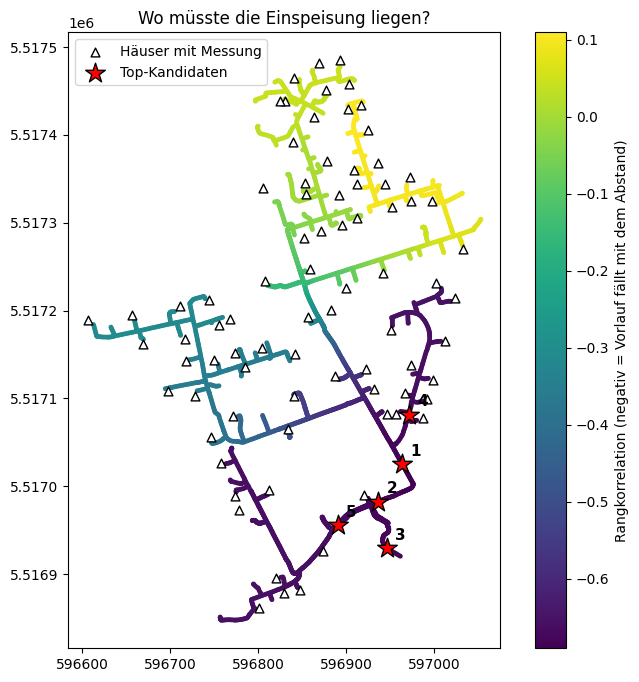

In [4]:


MIN_FLUSS = 40               # l/h: nur Stunden mit echtem Durchfluss
MONATE = [12, 1, 2]   # Heizsaison
MIN_HAEUSER_STUNDE = 20      # Stunden mit weniger Häusern werden nicht benutzt
MIN_STUNDEN = 200            # Häuser mit weniger Stunden werden nicht benutzt
ABSTAND_M = 50               # Kandidaten für die Top-Liste müssen so weit auseinander liegen

if "Gp" not in globals() or "snap" not in globals():
    raise SystemExit("Gp/snap fehlen: erst den Dashboard-Export (%run -i dashboard_export.py) laufen lassen.")
if not isinstance(xy, np.ndarray):
    raise SystemExit("`xy` wurde überschrieben (z. B. von der Graph-Zeichenzelle): Dashboard-Export erneut laufen lassen.")

nz = norm_z if "norm_z" in globals() else (lambda s: "".join(ch for ch in str(s) if ch.isdigit()).lstrip("0"))
zaehler_von = {r.edge_node: [nz(z) for z in str(r.zaehler).split(",") if nz(z)] for r in knoten.itertuples()}

# 1) Pro Haus: mittlere Abweichung des Vorlaufs vom Stundenmittel aller Häuser
spalten = {}
for r in knoten.itertuples():
    if r.edge_node not in nid:
        continue
    ds = [serien[z] for z in zaehler_von.get(r.edge_node, []) if z in serien]
    if ds:
        t = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)
        spalten[r.edge_node] = t[t.index.month.isin(MONATE)]
T = pd.DataFrame(spalten)
T = T[T.notna().sum(axis=1) >= MIN_HAEUSER_STUNDE]
abw = T.sub(T.mean(axis=1), axis=0)
delta = abw.mean()[abw.notna().sum() >= MIN_STUNDEN]
haeuser = list(delta.index)
print(f"Häuser: {len(haeuser)} | Stunden: {len(T)} | Spanne der Abweichung: {delta.min():.2f} bis {delta.max():.2f} K")

# 2) Rohrabstand von jedem Haus zu jedem Punkt im Rohrnetz
V = list(Gp.nodes)
vi = {v: i for i, v in enumerate(V)}
D = np.full((len(haeuser), len(V)), np.inf)
for k, h in enumerate(haeuser):
    for v, x in nx.single_source_dijkstra_path_length(Gp, snap[nid[h]], weight="len").items():
        D[k, vi[v]] = x
ok = np.isfinite(D).all(axis=0)
Dk = D[:, ok]
Vk = [V[i] for i in np.where(ok)[0]]

# 3) Rangkorrelation Abweichung gegen Abstand: an der Quelle fällt der Vorlauf mit dem Abstand (negativ)
rd0 = rankdata(delta.values) - (len(delta) + 1) / 2
RD0 = rankdata(Dk, axis=0) - (len(delta) + 1) / 2
nenner = np.sqrt((rd0 ** 2).sum() * (RD0 ** 2).sum(axis=0))
score = (rd0[:, None] * RD0).sum(axis=0) / nenner

rng = np.random.default_rng(1)
zufall = [((rng.permutation(rd0)[:, None] * RD0).sum(axis=0) / nenner).min() for _ in range(300)]

# 4) Top-Kandidaten, räumlich getrennt
xyv = np.array(Vk)
top = []
for i in np.argsort(score):
    if all(np.hypot(*(xyv[i] - xyv[j])) > ABSTAND_M for j in top):
        top.append(i)
    if len(top) == 5:
        break

G0 = G_orig if "G_orig" in globals() else G
namen = [n for n in nodes]
xy_n = np.array([xy[nid[n]] for n in namen])
zeilen = []
for rang, i in enumerate(top, 1):
    d = nx.single_source_dijkstra_path_length(Gp, Vk[i], weight="len")
    stimmt = widerspricht = 0
    for u, v in G0.edges:
        if u in nid and v in nid and snap[nid[u]] in d and snap[nid[v]] in d:
            if d[snap[nid[u]]] <= d[snap[nid[v]]]:
                stimmt += 1
            else:
                widerspricht += 1
    nah = int(np.argmin(np.hypot(*(xy_n - xyv[i]).T)))
    lon, lat = tr.transform(*Vk[i])
    zeilen.append({"rang": rang, "korrelation": round(score[i], 2),
                   "K_pro_100m": round(np.polyfit(Dk[:, i], delta.values, 1)[0] * 100, 2),
                   "lat": round(lat, 6), "lon": round(lon, 6),
                   "naechster_node": str(roh.get(namen[nah], namen[nah])),
                   "abstand_zum_node_m": round(float(np.hypot(*(xy_n[nah] - xyv[i]))), 0),
                   "kanten_stimmen": stimmt, "kanten_widersprechen": widerspricht})
erg = pd.DataFrame(zeilen)
print(f"\nBeste Korrelation: {score.min():.2f} | bei vertauschten Häusern erreicht man zufällig: "
      f"{np.median(zufall):.2f} (Median), {np.quantile(zufall, 0.05):.2f} (5%-Grenze)")
display(erg)

# 5) Karte: Farbe = Korrelation, wenn die Quelle dort läge
fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(xyv[:, 0], xyv[:, 1], c=score, s=6, cmap="viridis")
hx = np.array([xy[nid[h]] for h in haeuser])
ax.scatter(hx[:, 0], hx[:, 1], marker="^", c="white", edgecolors="black", s=40, label="Häuser mit Messung")
ax.scatter(xyv[top, 0], xyv[top, 1], marker="*", c="red", s=220, edgecolors="black", label="Top-Kandidaten")
for rang, i in enumerate(top, 1):
    ax.annotate(str(rang), xyv[i], xytext=(6, 6), textcoords="offset points", fontsize=11, weight="bold")
ax.set_aspect("equal"); ax.legend(loc="best")
plt.colorbar(sc, label="Rangkorrelation (negativ = Vorlauf fällt mit dem Abstand)")
ax.set_title("Wo müsste die Einspeisung liegen?")
plt.show()

### 2. Erzeuger als Quelle festlegen und Fließrichtung ausrichten

**Idee:** Laut Expertenwissen ist der Knoten „Erzeuger (Annahme)“ die tatsächliche Einspeisung. Alle Leitungen werden so ausgerichtet, dass sie von diesem Knoten wegzeigen.

> Vorher den Dashboard-Export ausführen, damit das Netz im Ausgangszustand ist.

1. **Prüfen:** Ist der Knoten „Erzeuger (Annahme)“ im Netz vorhanden? Sonst Abbruch mit Hinweis.
2. **Sichern:** Kopie des ursprünglichen Netzes anlegen.
3. **Abstand zählen:** Für jeden Knoten wird gezählt, wie viele Leitungen er vom Erzeuger entfernt ist (Richtung egal).
4. **Leitungen ausrichten:** Jede Leitung zeigt vom näheren zum weiter entfernten Knoten. Bei gleichem Abstand entscheidet der Name.
5. **Kontrolle:** Ausgabe, wie viele Leitungen umgedreht wurden, welche Knoten vom Erzeuger aus nicht erreichbar sind und welche Knoten keine eingehende Leitung haben (im Idealfall nur der Erzeuger).

In [5]:
QUELLE = "Erzeuger (Annahme)"   # von Experten bestätigt: dieser Knoten ist die Einspeisung
ADRESSE = "hans-zander-weg 14"  # Node mit der echten Adresse des Erzeugers (Spalte "node")
QUELLE_KOORD = None             # optional fest: (lat, lon), z. B. (49.79, 9.95); None = Position aus den Daten behalten

if QUELLE not in G:
    raise SystemExit(f"'{QUELLE}' fehlt im Netz: Dashboard-Export erneut laufen lassen.")

# 0) Adress-Node in den Erzeuger einbauen: nur Leitungen und Name übernehmen, Position des Erzeugers bleibt
if ADRESSE in G:
    roh[QUELLE] = f"Erzeuger ({roh.get(ADRESSE, ADRESSE)})"
    G = nx.contracted_nodes(G, QUELLE, ADRESSE, self_loops=False, copy=True)
    pos.pop(ADRESSE, None)
    print(f"'{ADRESSE}' mit '{QUELLE}' zusammengeführt")
if QUELLE_KOORD is not None:
    pos[QUELLE] = tuple(QUELLE_KOORD)
print("Position Erzeuger:", pos[QUELLE])

G_orig = G.copy()

# 1) Abstand jedes Nodes zur Quelle (in Kanten, Richtung egal)
U = G_orig.to_undirected()
print("Anschluss:", sorted(U[QUELLE], key=str))
tiefe = nx.single_source_shortest_path_length(U, QUELLE)

# 2) Alle Kanten vom Erzeuger weg ausrichten
G_neu = nx.DiGraph()
G_neu.add_nodes_from(G_orig.nodes(data=True))
gedreht = 0
for u, v, d in G_orig.edges(data=True):
    if u in tiefe and v in tiefe:
        a, b = (u, v) if (tiefe[u], str(u)) <= (tiefe[v], str(v)) else (v, u)
        gedreht += (a, b) != (u, v)
    else:
        a, b = u, v
    G_neu.add_edge(a, b, **d)
G = G_neu

print(f"{gedreht} von {G_orig.number_of_edges()} Kanten gedreht")
print("nicht erreichbar:", [n for n in G_orig if n not in tiefe])
print("Nodes ohne eingehende Kante:", [n for n in G if G.in_degree(n) == 0])

'hans-zander-weg 14' mit 'Erzeuger (Annahme)' zusammengeführt
Position Erzeuger: (49.797272209077974, 10.34719392379232)
Anschluss: ['hans-zander-weg 1', 'hans-zander-weg 12']
54 von 111 Kanten gedreht
nicht erreichbar: []
Nodes ohne eingehende Kante: ['Erzeuger (Annahme)']


### 3. Plausibilitätstest: Stimmt die Fließrichtung?

**Idee:** Der Erzeuger-Knoten ist laut Experten bestätigt. Wir prüfen trotzdem mit den Messdaten, ob die daraus abgeleitete Fließrichtung plausibel ist. Wasser kühlt auf dem Weg ab, also sollte der Vorlauf in Pfeilrichtung sinken.

1. **Einstellungen:** Durchfluss ab 20 l/h, Monate November bis März, mindestens 100 gemeinsame Messstunden pro Leitung. Unterschiede unter 0,5 K gelten als unklar.
2. **Vorlauf pro Knoten:** Zeitreihe aus den zugehörigen Zählern (bei mehreren gemittelt).
3. **Leitungen testen:** Für jede Leitung mit Messungen an beiden Enden: Median von „Vorlauf am Anfang minus Vorlauf am Ende“.
   - deutlich positiv → Richtung passt
   - deutlich negativ → Richtung verdächtig
   - dazwischen → unklar
4. **Vergleich:**
   - **A:** Richtungen wie in der Datei
   - **B:** Richtungen vom Erzeuger weg
   
   Hat B mehr passende und weniger verdächtige Leitungen, stützen die Messdaten die Angabe der Experten.
5. **Verdächtige Leitungen:** Die 10 Leitungen aus B, bei denen der Vorlauf in Pfeilrichtung am stärksten steigt. Hinweise auf mögliche Fehler im Netz (z. B. falsche Anschlüsse, fehlende Leitungen, vertauschte Zähler).

In [6]:
MIN_FLUSS = 20
MONATE = [11, 12, 1, 2, 3]
MIN_STUNDEN = 100
SCHWELLE_K = 0.5

nz = norm_z if "norm_z" in globals() else (lambda s: "".join(ch for ch in str(s) if ch.isdigit()).lstrip("0"))
zaehler_von = {r.edge_node: [nz(z) for z in str(r.zaehler).split(",") if nz(z)] for r in knoten.itertuples()}

_cache = {}
def vorlauf(n):
    if n not in _cache:
        ds = [serien[z] for z in zaehler_von.get(n, []) if z in serien]
        if not ds:
            _cache[n] = None
        else:
            f = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)
            _cache[n] = f[f.index.month.isin(MONATE)]
    return _cache[n]

def kantentest(Gx):
    zeilen = []
    for u, v in Gx.edges:
        a, b = vorlauf(u), vorlauf(v)
        if a is None or b is None:
            continue
        d = (a - b).dropna()
        if len(d) >= MIN_STUNDEN:
            zeilen.append({"von": roh.get(u, u), "nach": roh.get(v, v),
                           "stunden": len(d), "median_K": round(d.median(), 2)})
    return pd.DataFrame(zeilen)

ergebnis = {}
for name, Gx in [("A: Dateirichtung", G_orig), ("B: vom Erzeuger weg", G)]:
    t = kantentest(Gx)
    ok = int((t["median_K"] > SCHWELLE_K).sum())
    umg = int((t["median_K"] < -SCHWELLE_K).sum())
    ergebnis[name] = t
    print(f"{name}: bewertet {len(t)} von {Gx.number_of_edges()} Kanten | "
          f"Vorlauf sinkt in Pfeilrichtung: {ok} | steigt: {umg} | unklar: {len(t) - ok - umg}")

print("\nVerdächtigste Kanten in B (Vorlauf steigt am stärksten in Pfeilrichtung):")
display(ergebnis["B: vom Erzeuger weg"].sort_values("median_K").head(10))

C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\3523151324.py:16: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  f = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)


A: Dateirichtung: bewertet 58 von 111 Kanten | Vorlauf sinkt in Pfeilrichtung: 23 | steigt: 25 | unklar: 10
B: vom Erzeuger weg: bewertet 58 von 110 Kanten | Vorlauf sinkt in Pfeilrichtung: 27 | steigt: 21 | unklar: 10

Verdächtigste Kanten in B (Vorlauf steigt am stärksten in Pfeilrichtung):


,von,nach,stunden,median_K
24,Magnolienweg 2,Asternweg 37,3837,-5.6
57,Rosenstraße 9,Rosenstraße 8,401,-5.0
46,Nelkenstraße 6,Nelkenstraße 1,5496,-3.3
9,Asternweg 29,Asternweg 22,3155,-3.2
40,Fliederstraße 25,Fliederstraße 27,2682,-2.9
19,Irisweg 9,Irisweg 9a,3242,-2.1
32,Blumenstraße 4,Blumenstraße 9,2641,-1.9
25,Asternweg 39,Magnolienweg 2,3447,-1.8
28,Tulpenstraße 3,Blütenstraße 14,5771,-1.7
43,Fliederstraße 28,Fliederstraße 31,3104,-1.7


### 4. Erzeuger ans Rohrnetz anbinden und Anschlüsse prüfen

**Idee:** Der bestätigte Erzeuger wird auf das echte Rohrnetz gesetzt. Danach prüfen wir, ob alle Häuser sinnvoll mit ihm verbunden sind.

1. **Erzeuger aufs Rohr setzen:** Koordinaten in Meter umrechnen und den nächsten Rohrpunkt suchen. Ausgabe: Abstand zum Rohr.
2. **Netzstück bestimmen:** Nur der Teil des Rohrnetzes, der mit dem Erzeuger verbunden ist. Zusätzlich die Anzahl der Ringe (Häuser, die auf mehreren Wegen erreichbar sind).
3. **Rohrweg zu jedem Haus:** Strecke entlang der Rohre vom Erzeuger bis zur Anschlussstelle jedes Hauses, plus Abstand vom Haus zu dieser Stelle (Anschlussabstand).
4. **Kontrollen:**
   - Häuser ohne Verbindung zum Erzeuger
   - typischer und größter Anschlussabstand (sehr große Werte → Zuordnung prüfen)
   - Häuser, die sich eine Anschlussstelle teilen
5. **Listen zum Nachprüfen:** die 10 Häuser mit dem größten Anschlussabstand und alle Häuser ohne Verbindung zum Erzeuger.

In [7]:
# Erzeuger auf das Rohrnetz legen
QUELLE_POS = pos[QUELLE]   # Position des bestätigten Erzeugers (lat, lon)
t = Transformer.from_crs(4326, 25832, always_xy=True)
qx, qy = t.transform(QUELLE_POS[1], QUELLE_POS[0])
d_q, i_q = cKDTree(np.array(V)).query([qx, qy])
q_v = V[i_q]
print(f"Erzeuger liegt {d_q:.0f} m neben dem nächsten Rohrpunkt")

# Rohrnetzteil, an dem der Erzeuger hängt
teil = Gp.subgraph(nx.node_connected_component(Gp, q_v))
ringe = teil.number_of_edges() - teil.number_of_nodes() + 1
print(f"Rohrnetzteil: {teil.number_of_nodes()} Punkte | unabhängige Ringe: {ringe}")

# Rohrweg Erzeuger -> jede Anschlussstelle
dq = nx.single_source_dijkstra_path_length(Gp, q_v, weight="len")
haeuser = [n for n in G if n != QUELLE and n in nid]
zeilen = []
for h in haeuser:
    i = nid[h]
    zeilen.append({"haus": roh.get(h, h), "anschluss_m": round(float(dist_[i]), 1),
                   "rohrweg_m": round(dq.get(snap[i], np.nan)), "stelle": snap[i]})
ph = pd.DataFrame(zeilen)

print(f"\nHäuser: {len(ph)} | nicht am Erzeuger-Rohrnetz: {int(ph['rohrweg_m'].isna().sum())}")
print(f"Anschlussabstand: Median {ph['anschluss_m'].median():.0f} m, größter {ph['anschluss_m'].max():.0f} m")
print(f"Häuser an einer gemeinsamen Stelle: {int(ph.duplicated('stelle', keep=False).sum())}")
print("\nGrößte Anschlussabstände (Zuordnung prüfen):")
display(ph.sort_values("anschluss_m", ascending=False).head(10).drop(columns="stelle"))
print("Häuser ohne Verbindung zum Erzeuger:")
display(ph[ph["rohrweg_m"].isna()].drop(columns="stelle"))

Erzeuger liegt 6 m neben dem nächsten Rohrpunkt
Rohrnetzteil: 3803 Punkte | unabhängige Ringe: 2013

Häuser: 109 | nicht am Erzeuger-Rohrnetz: 0
Anschlussabstand: Median 6 m, größter 21 m
Häuser an einer gemeinsamen Stelle: 9

Größte Anschlussabstände (Zuordnung prüfen):


,haus,anschluss_m,rohrweg_m
23,Mohnweg 19a,20.6,457
103,Rosenstraße 7b,18.9,233
54,Blütenstraße 14,16.0,301
19,Asternweg 22,14.3,486
34,Irisweg 3,14.2,692
49,Fliederstraße 7,13.7,476
104,Rosenstraße 7a,12.7,277
24,Asternweg 25,11.6,421
51,Fliederstraße 11,11.0,415
60,Blumenstraße 8,10.9,367


Häuser ohne Verbindung zum Erzeuger:


,haus,anschluss_m,rohrweg_m


### 5. Rohrbaum vom Erzeuger zu allen Häusern

**Idee:** Aus dem Rohrnetz wird ein Baum gebaut: für jedes Haus der kürzeste Rohrweg vom Erzeuger. So sieht man, welche Leitungen tatsächlich zur Versorgung genutzt werden und welche Häuser hintereinander liegen.

> Vorher die Kantentest-Zelle ausführen (sie definiert `vorlauf()` und die Einstellungen).

1. **Häuser auswählen:** nur Knoten mit Zähler. Verteiler ohne Zähler fallen raus. Ausgabe: Anzahl Häuser, davon ohne Messdatei.
2. **Kürzeste Wege:** vom Erzeuger entlang der Rohre zu jeder Anschlussstelle. Zusammen ergeben sie einen Baum.
3. **Schlüsselpunkte:** Erzeuger, Anschlussstellen der Häuser und Abzweige (wo sich der Weg teilt).
4. **Abschnitte:** Rohrstücke zwischen zwei Schlüsselpunkten, mit Länge und Anzahl der Häuser, die dahinter versorgt werden. Ausgabe: genutzte Rohrlänge im Vergleich zum ganzen Plan.
5. **Test gegen die Messdaten:** Für jedes Haus wird das nächste Haus flussaufwärts gesucht. Dessen Vorlauf sollte wärmer sein.
   - deutlich wärmer → passt
   - deutlich kälter → verdächtig
   - dazwischen → unklar
   
   Die 10 auffälligsten Paare werden angezeigt.
6. **Bild:** Baum in Rot (je dicker, desto mehr Häuser dahinter), Häuser als blaue Punkte mit grauer Anschlusslinie, Erzeuger als goldener Stern. Gespeichert als `rohrbaum.png`.

Häuser mit Zähler: 80 | davon ohne Messdatei: 0 | entfernt (ohne Zähler): 29


Baum: 154 Schlüsselpunkte | 153 Abschnitte | 3801 m Rohr genutzt (von 9577 m im Plan)
Häuser: 80 | Anschlussstellen: 80 | Abzweige: 73

Test 'oberes Haus wärmer': bewertet 38 | ja: 36 | nein: 0 | unklar: 2


,oben,unten,median_K
33,Blütenstraße 15,Blütenstraße 24,-0.5
35,Blütenstraße 15,Blütenstraße 11,-0.4
10,Asternweg 18,Anemonenweg 2,0.9
18,Blütenstraße 14,Fliederstraße 18,0.9
34,Blütenstraße 15,Blütenstraße 20,0.9
15,Blütenstraße 14,Asternweg 27,1.1
31,Blütenstraße 14,Fliederstraße 9,1.4
9,Blütenstraße 14,Anemonenweg 3,1.6
37,Hans-Zander-Weg 8,Hans-Zander-Weg 6,1.7
14,Blütenstraße 14,Asternweg 18,2.2


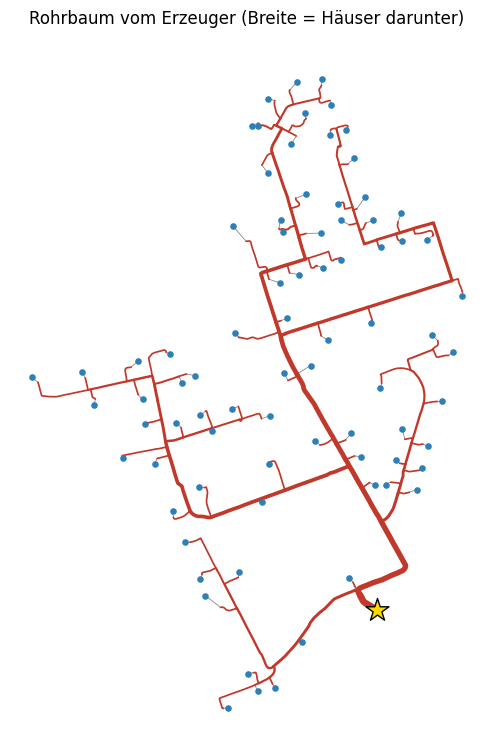

In [8]:
# Rohrbaum vom Erzeuger zu allen Häusern
if "vorlauf" not in globals():
    raise SystemExit("Erst die Kantentest-Zelle laufen lassen (sie definiert vorlauf() und MONATE).")

# nur Knoten mit Zähler (Verteiler ohne Zähler fliegen raus, der Erzeuger kommt separat über q_v)
haeuser = [n for n in G if n != QUELLE and n in nid and zaehler_von.get(n)]
ohne_daten = [n for n in haeuser if not any(z in serien for z in zaehler_von[n])]
print(f"Häuser mit Zähler: {len(haeuser)} | davon ohne Messdatei: {len(ohne_daten)} "
      f"| entfernt (ohne Zähler): {sum(1 for n in G if n != QUELLE and n in nid) - len(haeuser)}")
dist_q, pfade = nx.single_source_dijkstra(Gp, q_v, weight="len")

# 1) Baum: Wege vom Erzeuger zu allen Anschlussstellen
snap_von = {h: snap[nid[h]] for h in haeuser}
parent = {}
for s in set(snap_von.values()):
    p = pfade[s]
    for a, b in zip(p[:-1], p[1:]):
        parent[b] = a
kinder = {}
for b, a in parent.items():
    kinder.setdefault(a, []).append(b)
haus_an = {}
for h, s in snap_von.items():
    haus_an.setdefault(s, []).append(h)

# 2) Schlüsselpunkte: Erzeuger, Anschlussstellen, Verzweigungen
schluessel = {q_v} | set(haus_an) | {v for v, k in kinder.items() if len(k) >= 2}

# 3) Straßenabschnitte zwischen Schlüsselpunkten
T = nx.DiGraph()
for v in schluessel:
    T.add_node(v, art="quelle" if v == q_v else ("haus_stelle" if v in haus_an else "abzweig"))
for v in schluessel - {q_v}:
    weg = [v]
    u = parent[v]
    while u not in schluessel:
        weg.append(u)
        u = parent[u]
    weg.append(u)
    T.add_edge(u, v, laenge=dist_q[v] - dist_q[u], pfad=weg[::-1])
for u, v in T.edges:
    T[u][v]["n_haeuser"] = sum(len(haus_an.get(d, [])) for d in nx.descendants(T, v) | {v})

print(f"Baum: {T.number_of_nodes()} Schlüsselpunkte | {T.number_of_edges()} Abschnitte | "
      f"{sum(d['laenge'] for *_, d in T.edges(data=True)):.0f} m Rohr genutzt (von {sum(d['len'] for *_, d in Gp.edges(data=True)):.0f} m im Plan)")
print(f"Häuser: {len(haeuser)} | Anschlussstellen: {len(haus_an)} | Abzweige: {sum(1 for _, d in T.nodes(data=True) if d['art'] == 'abzweig')}")

# 4) Test gegen die Daten: ist das nächste Haus flussaufwärts wärmer?
def oberhaus(s):
    while s != q_v:
        s = next(T.predecessors(s))
        if s in haus_an:
            return haus_an[s]
    return []

zeilen = []
for h, s in snap_von.items():
    for o in oberhaus(s):
        a, b = vorlauf(o), vorlauf(h)
        if a is None or b is None:
            continue
        d = (a - b).dropna()
        if len(d) >= MIN_STUNDEN:
            zeilen.append({"oben": roh.get(o, o), "unten": roh.get(h, h), "median_K": round(d.median(), 2)})
            break
tt = pd.DataFrame(zeilen)
if len(tt):
    ok = int((tt.median_K > SCHWELLE_K).sum()); umg = int((tt.median_K < -SCHWELLE_K).sum())
    print(f"\nTest 'oberes Haus wärmer': bewertet {len(tt)} | ja: {ok} | nein: {umg} | unklar: {len(tt) - ok - umg}")
    display(tt.sort_values("median_K").head(10))

# 5) Bild
fig, ax = plt.subplots(figsize=(11, 9))
mx = max(d["n_haeuser"] for *_, d in T.edges(data=True))
for u, v, d in T.edges(data=True):
    P = np.array(d["pfad"])
    ax.plot(P[:, 0], P[:, 1], color="#c0392b", lw=0.8 + 4 * np.sqrt(d["n_haeuser"] / mx), solid_capstyle="round", zorder=2)
for h in haeuser:
    x, y = xy[nid[h]]
    sx, sy = snap_von[h]
    ax.plot([x, sx], [y, sy], color="#888", lw=0.6, zorder=1)
    ax.scatter([x], [y], s=14, color="#2c7fb8", zorder=3)
ax.scatter([q_v[0]], [q_v[1]], marker="*", s=300, color="gold", edgecolor="k", zorder=4)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Rohrbaum vom Erzeuger (Breite = Häuser darunter)")
plt.savefig("rohrbaum.png", dpi=150, bbox_inches="tight"); plt.show()

## Dashboard auf dem Rohrbaum

**Idee:** Das bestehende Dashboard (`dashboard_export.py`) bekommt statt der Kantendatei den Rohrbaum als Netz. So folgen Leitungen und Fließanimation dem echten Weg vom Erzeuger über die Straßenleitungen zu den Hausanschlüssen.

1. **Graph bauen:** Erzeuger → Einspeisepunkt am Rohr → Abzweige und Anschlussstellen → Häuser. Die Rohrbaum-Punkte werden als Nodes ohne Zähler eingefügt.
2. **Export ausführen:** in einem eigenen Namensraum, damit die Analyse-Variablen im Notebook (z. B. `nid`, `snap`, `Gp`) nicht überschrieben werden.
3. **Speichern:** als `fernwaerme_dashboard_rohrbaum.html`. Die Erklärtexte im Dashboard werden an den Rohrbaum angepasst, das alte Dashboard bleibt erhalten.

In [25]:
# Dashboard mit dem Rohrbaum statt der Kantendatei
PUNKTE_ZEIGEN = False   # Abzweige und Anschlussstellen im Dashboard als graue Punkte zeigen?

t_ll = Transformer.from_crs(25832, 4326, always_xy=True)
def ll_punkt(p):
    lo, la = t_ll.transform(*p)
    return (la, lo)

# 1) Graph fürs Dashboard: Erzeuger -> Rohrbaum-Punkte -> Häuser
name_von = {v: f"Rohr {i}" for i, v in enumerate(T.nodes)}
if set(name_von.values()) & set(G.nodes):
    raise SystemExit("Namenskonflikt: ein Node im Netz heißt schon 'Rohr …'.")
ART = {"quelle": "Einspeisepunkt am Rohr", "abzweig": "Abzweig", "haus_stelle": "Anschlussstelle"}

G_dash = nx.DiGraph()
pos_dash, roh_dash = dict(pos), dict(roh)
for v, d in T.nodes(data=True):
    G_dash.add_node(name_von[v])
    pos_dash[name_von[v]] = ll_punkt(v)
    roh_dash[name_von[v]] = ART[d["art"]]
G_dash.add_edges_from((name_von[u], name_von[v]) for u, v in T.edges)
G_dash.add_edge(QUELLE, name_von[q_v])
for s, hs in haus_an.items():
    for h in hs:
        if h in pos:
            G_dash.add_edge(name_von[s], h)

print(f"Dashboard-Graph: {G_dash.number_of_nodes()} Nodes, {G_dash.number_of_edges()} Kanten | "
      f"Baum: {nx.is_arborescence(G_dash)} | Quellen: {[n for n in G_dash if G_dash.in_degree(n) == 0]}")

# 2) Export in eigenem Namensraum ausführen (überschreibt keine Notebook-Variablen wie nid, snap, Gp, xy)
alt = Path("fernwaerme_dashboard.html")
alt_inhalt = alt.read_bytes() if alt.exists() else None

ns = runpy.run_path("dashboard_export.py", init_globals={
    "serien": serien, "knoten": knoten, "G": G_dash, "pos": pos_dash, "roh": roh_dash,
    **{k: globals()[k] for k in ("norm_z", "linien", "kml_linien", "geschaetzt") if k in globals()}})

# 3) Unter eigenem Namen speichern, Erklärtexte anpassen, altes Dashboard wiederherstellen
html_ = alt.read_text(encoding="utf-8")
ersetzungen = [
    ("<title>Fernwärme-Dashboard</title>", "<title>Fernwärme-Dashboard (Rohrbaum)</title>"),
    ("<strong>Fernwärme-Dashboard</strong>", "<strong>Fernwärme-Dashboard (Rohrbaum)</strong>"),
    ("Die Pfeilrichtung der Bewegung folgt der Richtung in deiner Kantendatei.",
     "Die Bewegung folgt dem Rohrbaum vom Erzeuger weg."),
    ("Wo mehrere Leitungen in einen Punkt münden, wird die Last gleichmäßig aufgeteilt. Das ist eine Annahme.",
     "Jedes Haus ist über den kürzesten Rohrweg mit dem Erzeuger verbunden. Ringe im Netz werden dabei aufgelöst, das ist eine Annahme."),
    ("Graue Punkte sind Abzweige ohne Zähler. Punkte mit rotem Ring sind Quellen im Graphen. Linien sind Luftlinien, nicht der Rohrverlauf.",
     ("Graue Punkte sind Abzweige und Anschlussstellen am Rohr. " if PUNKTE_ZEIGEN else "")
     + "Der Punkt mit rotem Ring ist der Erzeuger. Leitungen folgen dem Rohrplan, Hausanschlüsse sind gerade Linien."),
]
if not PUNKTE_ZEIGEN:   # Punkte ohne Zähler unsichtbar machen, Erzeuger bleibt sichtbar
    ersetzungen += [
        ("const r = n.m >= 0 ? 6 + 2*Math.min((n.k||1)-1, 3) : 3.5;",
         "const r = n.m >= 0 ? 6 + 2*Math.min((n.k||1)-1, 3) : (n.src ? 7 : 0);"),
        ("{radius:r, weight:n.src ? 3 : 1,",
         "{radius:r, weight:n.src ? 3 : (n.m < 0 ? 0 : 1),"),
        ("if (n.m < 0){ n.mk.setStyle({fillColor:'#aaaaaa', fillOpacity:0.8}); return; }",
         "if (n.m < 0){ return; }"),
    ]
for a, b in ersetzungen:
    if a not in html_:
        print("Hinweis: Textstelle nicht gefunden, Dashboard-Version geändert?", a[:50])
    html_ = html_.replace(a, b)
ziel = Path("fernwaerme_dashboard_rohrbaum.html")
ziel.write_text(html_, encoding="utf-8")
if alt_inhalt is not None:
    alt.write_bytes(alt_inhalt)
else:
    alt.unlink()
print("gespeichert:", ziel.resolve())

Dashboard-Graph: 235 Nodes, 234 Kanten | Baum: True | Quellen: ['Erzeuger (Annahme)']
Hintergrund: 109 Gebäudelinien (Typ 6), 743 Rohrplan-Linien (Shapefile und KML)
Kanten auf Rohren: 153 von 234 | zu weit vom Rohrnetz: 0 | ohne Rohrverbindung: 81 (diese bleiben gerade Linien)
Geschrieben: C:\Users\pauli\Documents\Information Systems\2026 SoSe\Projektseminar\projektseminar-1\notebooks\fernwaerme_dashboard.html  (10.7 MB)
Zeitraum: 2024-01-01 00:00:00 bis 2025-05-31 23:00:00 (12408 Stunden)
Häuser mit Zeitreihe: 80 | Nodes: 235 | Kanten: 234
Graph ist ohne Kreise: True | Quellen: 1
WARNUNG: 10446 Werte lagen außerhalb des Speicherbereichs und wurden gekappt.
Startzeitpunkt im Dashboard: 2024-01-04 08:00:00
Datei im Browser öffnen (Doppelklick). Karte und Hintergrundkacheln brauchen Internet (Leaflet und Webkarte Bayern).
Hintergrund oben rechts in der Karte umschaltbar. OpenStreetMap geht nur, wenn die Datei über einen lokalen Server geöffnet wird:
  Terminal im Ordner der Datei:  pyth

### 6. Knoten ohne Zähler auflisten

**Idee:** Übersicht, welche Knoten im Netz keine Messdaten haben.

1. **Knoten mit Zähler bestimmen:** alle Knoten, die in der Zählertabelle vorkommen.
2. **Tabelle bauen:** für jeden Knoten Name, Anzeigename, ob ein Zähler vorhanden ist, und Koordinaten.
3. **Ausgabe:** Anzahl der Knoten gesamt, mit und ohne Zähler, plus Liste aller Knoten ohne Zähler.

**Wofür ist das nützlich?**
- **Erzeuger prüfen:** Er hat keinen Zähler und sollte genau einmal in der Liste stehen.
- **Häuser ohne Messdaten:** Die übrigen Einträge sind Häuser aus der ursprünglichen Kantenliste, für die es keine Zählerdaten gibt. Sie werden im Rohrbaum und in den Tests nicht berücksichtigt.

**Hinweis zur Kantenliste:** Die Kanten verbinden Häuser direkt miteinander. Im Fernwärmenetz fließt das Wasser aber von der Straßenleitung ins Haus und wieder zurück, nicht von Haus zu Haus. Für die Fließwege ist deshalb der Rohrbaum auf dem Rohrnetz maßgeblich, nicht die Kantenliste.

In [10]:
mit_zaehler = set(knoten["edge_node"])
zeilen = []
for n in G:
    zeilen.append({
        "node": n,
        "anzeige": roh.get(n, n),
        "hat_zaehler": n in mit_zaehler,
        "lat": round(pos[n][0], 6) if n in pos else None,
        "lon": round(pos[n][1], 6) if n in pos else None,
    })
t = pd.DataFrame(zeilen)
print(f"Nodes im Graphen: {len(t)} | mit Zähler: {int(t.hat_zaehler.sum())} | ohne Zähler: {int((~t.hat_zaehler).sum())}")
display(t[~t.hat_zaehler])

Nodes im Graphen: 110 | mit Zähler: 80 | ohne Zähler: 30


,node,anzeige,hat_zaehler,lat,lon
5,ginsterweg 24,Ginsterweg 24,False,49.801550,10.345195
8,ginsterweg 6,Ginsterweg 6,False,49.801408,10.346057
9,ginsterweg 14,Ginsterweg 14,False,49.801408,10.346057
12,anemonenweg 5,Anemonenweg 5,False,49.801092,10.345900
13,anemonenweg 4,Anemonenweg 4,False,49.801025,10.346075
16,mohnweg 21,Mohnweg 21,False,49.800788,10.345561
17,anemonenweg 1,Anemonenweg 1,False,49.800608,10.345974
29,irisweg 8,Irisweg 8,False,49.801378,10.346759
31,irisweg 6,Irisweg 6,False,49.801136,10.346840
32,irisweg 5,Irisweg 5,False,49.801000,10.346761


## 7. Messreihen und feste Merkmale je Haus

**Idee:** Messdaten und Lage im Rohrbaum werden einmal in Arrays gepackt, auf denen alle folgenden Analysen aufbauen.

1. **Zeitraum:** stündlich von Januar 2024 bis Mai 2025 (oder `START`/`ENDE`, falls gesetzt).
2. **Messreihen pro Haus:** Vorlauf, Rücklauf, Spreizung, Durchfluss und Leistung. Mehrere Zähler: Durchfluss und Leistung addiert, Temperaturen gemittelt. Temperaturen nur bei mindestens 5 l/h.
3. **Feste Merkmale** je Haus und Rohrbaum-Punkt: Rohrweg zum Erzeuger, Anzahl Abzweigungen bis zum Erzeuger, Häuser dahinter, Spitzenleistung, Länge der Anschlussleitung.
4. **Zeitmerkmale:** Uhrzeit, Wochentag und Tag im Jahr als Sinus/Kosinus, damit z. B. 23 Uhr und 0 Uhr als benachbart gelten.

In [11]:
START_ = pd.Timestamp(START) if "START" in globals() else pd.Timestamp("2024-01-01 00:00")
ENDE_ = pd.Timestamp(ENDE) if "ENDE" in globals() else pd.Timestamp("2025-05-31 23:00")
zeiten = pd.date_range(START_, ENDE_, freq="h")
FLUSS_MIN = 5.0          # l/h: darunter sind Vorlauf/Rücklauf nicht aussagekräftig
MERKMALE = ["vor", "rueck", "spreizung", "fluss", "leistung"]

hausliste = [h for h in haeuser if any(z in serien for z in zaehler_von.get(h, []))]

def reihe(h):
    ds = []
    for z in zaehler_von[h]:
        if z in serien:
            d = serien[z]
            ds.append(d[~d.index.duplicated()].reindex(zeiten))
    fl = pd.concat([d["fluss"] for d in ds], axis=1).sum(axis=1, min_count=1)
    le = pd.concat([d["leistung"] for d in ds], axis=1).sum(axis=1, min_count=1)
    ok = [d["fluss"] > FLUSS_MIN for d in ds]
    vo = pd.concat([d["vor"].where(o) for d, o in zip(ds, ok)], axis=1).mean(axis=1)
    rk = pd.concat([d["rueck"].where(o) for d, o in zip(ds, ok)], axis=1).mean(axis=1)
    return np.column_stack([vo, rk, vo - rk, fl, le])

X = np.stack([reihe(h) for h in hausliste], axis=1).astype("float32")      # (Zeit, Häuser, Merkmale)
print(f"Zeitreihen: {X.shape[0]} Stunden x {X.shape[1]} Häuser x {X.shape[2]} Merkmale")
print("Anteil gültiger Werte je Merkmal:", dict(zip(MERKMALE, np.round(np.mean(~np.isnan(X), axis=(0, 1)), 2))))

# Knoten: Häuser (0..N-1) + Schlüsselpunkte des Rohrbaums T
N = len(hausliste)
tknoten = list(T.nodes)
tidx = {v: N + i for i, v in enumerate(tknoten)}

def unter(v):
    return sum(len(haus_an.get(d, [])) for d in nx.descendants(T, v) | {v})

statisch = np.zeros((N + len(tknoten), 5), dtype="float32")   # rohrweg_m, tiefe, haeuser_unter, leistung_p99, anschluss_m
for i, h in enumerate(hausliste):
    s = snap_von[h]
    statisch[i] = [dist_q.get(s, np.nan), len(nx.ancestors(T, s)), 1,
                   np.nanpercentile(X[:, i, 4], 99) if np.isfinite(X[:, i, 4]).any() else np.nan,
                   float(dist_[nid[h]])]
for v in tknoten:
    statisch[tidx[v]] = [dist_q.get(v, 0.0), len(nx.ancestors(T, v)), unter(v), np.nan, 0.0]

# Zeitmerkmale: Uhrzeit, Wochentag, Tag im Jahr als Sinus/Kosinus
h_ = zeiten.hour.values; w_ = zeiten.dayofweek.values; d_ = zeiten.dayofyear.values
zeit_feat = np.column_stack([np.sin(2*np.pi*h_/24), np.cos(2*np.pi*h_/24),
                             np.sin(2*np.pi*w_/7), np.cos(2*np.pi*w_/7),
                             np.sin(2*np.pi*d_/366), np.cos(2*np.pi*d_/366)]).astype("float32")

Zeitreihen: 12408 Stunden x 80 Häuser x 5 Merkmale
Anteil gültiger Werte je Merkmal: {'vor': np.float64(0.59), 'rueck': np.float64(0.59), 'spreizung': np.float64(0.59), 'fluss': np.float64(0.9), 'leistung': np.float64(0.9)}


## 8. Rohrbaum auf einer interaktiven Karte

**Idee:** Der Rohrbaum wird auf einer OpenStreetMap-Karte dargestellt, damit man Leitungen, Abzweige und Hausanschlüsse direkt im Straßenbild prüfen kann.

1. **Koordinaten umrechnen:** von Metern (UTM) zurück in Breiten- und Längengrad für die Karte.
2. **Karte anlegen:** zentriert auf den Erzeuger, mit Maßstab.
3. **Rohrabschnitte:** als Linien entlang der Straßen. Je dicker und röter, desto mehr Häuser hängen dahinter. Beim Drüberfahren: Länge und Anzahl Häuser.
4. **Abzweige:** kleine graue Punkte, wo sich die Leitung teilt, mit Anzahl der Äste.
5. **Häuser:** blaue Punkte, gestrichelt mit ihrer Anschlussstelle an der Straße verbunden. Beim Drüberfahren: Name des Hauses.
6. **Erzeuger:** rotes Flammen-Symbol an seiner echten Position, gestrichelt mit dem Rohrpunkt verbunden, an dem er angeschlossen ist.
7. **Speichern:** als `rohrbaum_karte.html` (im Browser öffnen) und direkt im Notebook angezeigt.

In [12]:
# Rohrbaum T auf einer Karte (folium)
t_ll = Transformer.from_crs(25832, 4326, always_xy=True)
def ll(x, y):
    lo, la = t_ll.transform(x, y)
    return (la, lo)

mitte = pos[QUELLE] if "QUELLE" in globals() and QUELLE in pos else next(iter(pos.values()))
karte = folium.Map(location=mitte, zoom_start=16, tiles="OpenStreetMap", control_scale=True)

# Abschnitte des Baums: Dicke und Farbe nach Anzahl Häuser dahinter
maxh = max((d["n_haeuser"] for _, _, d in T.edges(data=True)), default=1)
farbe = linear.YlOrRd_09.scale(0, maxh)
farbe.caption = "Häuser hinter dem Abschnitt"
for u, v, d in T.edges(data=True):
    pfad = [ll(x, y) for x, y in d["pfad"]]
    folium.PolyLine(pfad, color=farbe(d["n_haeuser"]), weight=2 + 5 * d["n_haeuser"] / maxh, opacity=0.9,
                    tooltip=f"{d['laenge']:.0f} m | {d['n_haeuser']} Häuser dahinter").add_to(karte)
farbe.add_to(karte)

# Abzweige (Knoten mit mehr als einem Kind) klein in grau
for v in T.nodes:
    if v != q_v and T.out_degree(v) >= 2:
        folium.CircleMarker(ll(*v), radius=3, color="#555", fill=True, fill_opacity=0.8,
                            tooltip=f"Abzweig, {T.out_degree(v)} Äste").add_to(karte)

# Häuser: Verbindung vom Anschlusspunkt zum Haus (gestrichelt) und Punkt
for s, hs in haus_an.items():
    for h in hs:
        if h in pos:
            folium.PolyLine([ll(*s), pos[h]], color="#2a6fdb", weight=1.5, dash_array="4").add_to(karte)
            folium.CircleMarker(pos[h], radius=5, color="#2a6fdb", fill=True, fill_opacity=0.9,
                                tooltip=str(roh.get(h, h))).add_to(karte)

# Quelle: an der echten Position des Erzeugers, gestrichelt mit dem Rohrpunkt verbunden
folium.PolyLine([pos[QUELLE], ll(*q_v)], color="red", weight=1.5, dash_array="4").add_to(karte)
folium.Marker(pos[QUELLE], icon=folium.Icon(color="red", icon="fire", prefix="fa"),
              tooltip=str(roh.get(QUELLE, QUELLE))).add_to(karte)

pfad_html = "rohrbaum_karte.html"
karte.save(pfad_html)
print("gespeichert:", pfad_html, "| Abschnitte:", T.number_of_edges())
karte          # zeigt die Karte direkt im Notebook

gespeichert: rohrbaum_karte.html | Abschnitte: 153


## Projektordner finden

**Idee:** Damit das Notebook eigene Module aus dem Ordner `src` (z. B. `weather.py`) importieren kann, muss Python wissen, wo der Projektordner liegt.

1. **Automatisch suchen:** Vom aktuellen Ordner aus nach oben wird der erste Ordner gesucht, der `src/weather.py` enthält.
2. **Fallback:** Wird nichts gefunden, wird ein fest eingetragener Pfad genutzt.
3. **Suchpfad:** Der Ordner wird Python bekannt gemacht, damit die Imports funktionieren.

In [13]:
# Repo-Ordner (enthält den Unterordner "src") suchen und in den Suchpfad legen
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "weather.py").exists()), None)
if ROOT is None:
    ROOT = Path(r"C:\Users\pauli\Documents\Information Systems\2026 SoSe\Projektseminar\projektseminar-1")    # <- hier den Repo-Ordner eintragen
sys.path.insert(0, str(ROOT))
print("Repo:", ROOT)

Repo: c:\Users\pauli\Documents\Information Systems\2026 SoSe\Projektseminar\projektseminar-1


## Rohrbaum: Haus oder Netz?

**Frage:** Liegt eine Abweichung am einzelnen Haus oder am Netz? Idee: Ein Haus mit seinen Nachbarn im Rohrbaum vergleichen.

**Was wir gebaut haben**
- Rohrbaum von der Quelle zu den 110 Häusern. 
- Kontrolle: Das obere Haus ist wärmer als das untere, bei 17 von 19 Paaren, bei keinem gegenläufig.

**Test** (79 Häuser, Daten vor dem 1.9.2024)
- Je Haus: Abweichung von seinem normalen Verhalten bei Außentemperatur und Tageszeit (Spreizung).
- Verglichen mit den 4 nächsten Nachbarn im Baum und mit zufälligen Häusern.

**Ergebnis**
- Alle Häuser schwanken gemeinsam (Korrelation ca. 0,36). Das ist ein Effekt im **ganzen Netz**.
- Nachbarn im Rohrbaum teilen nicht mehr als zufällige Häuser (0,37 gegen 0,36). Nach Abzug des Netz-Effekts bleibt fast nichts (0,03). Ein Effekt pro Strang ist **nicht nachweisbar**.
- Fehlererkennung mit Begehungslabels: nur **Ventil** liegt über Zufall (AUC ca. 0,65 bis 0,69, bei nur 10 Fällen unsicher). Der Nachbarvergleich bringt keine Verbesserung. Die übrigen Labels liegen bei Zufall.
- Das passt zum Ergebnis im Repo (NB 23: auffällige Stationen häufen sich im Netz nicht).

**Fazit:** Mit Tagesmitteln der Spreizung trennt der Rohrbaum „Haus oder Netz" nicht. Ein Abzug über alle Häuser reicht.

**Ideen für später**
1. Kurze Ereignisse (Stunden) statt Tagesmittel.
2. Sommernacht-Durchfluss für Ventil (im Repo AUC 0,89).
3. Andere Größen: Rücklauf, Vorlauf, Wärmeverlust pro 100 m.
4. Andere Nachbarschaft: alle Häuser unter demselben Abzweig.
5. Richtungstest: Folgen die Häuser unterhalb einem Haus, das oben abweicht?
6. GNN auf den Rohrbaum-Daten, erst wenn eine Größe mit Signal gefunden ist.
7. Unechte Abzweige durch parallele Vor-/Rücklaufleitungen zusammenführen.

**Grenzen:** Richtungen sind Annahmen. Der Baum ist kein hydraulisches Modell. Wenige Fälle (9 bis 30 je Label), Begehungen zu zufälligen Terminen.

### 1. Nachbarvergleich und Prüfung gegen Begehungen

- **Normales Verhalten:** Ridge-Regression je Haus auf Außentemperatur, Außentemperatur², Uhrzeit und Wochentag. Nur Stunden mit Durchfluss, Häuser mit mindestens 30 Tagen.
- **Vergleichbarkeit:** Residuen als Tagesmittel, je Haus robust standardisiert (Median und MAD), auf ±6 begrenzt.
- **Nachbarn:** die 4 Häuser mit kürzestem Rohrweg im Baum. Ein Tag zählt nur, wenn mindestens 2 Nachbarn Werte haben.
- **Aufteilung:** Netzanteil = Mittel der Nachbarn, Hausanteil = Haus minus Netzanteil.
- **Auffällige Tage:** Hausanteil über 2 bzw. Netzanteil über 1,5 (in z-Einheiten).
- **Labels:** Zuordnung über die erste Zählernummer des Hauses. Bewertet werden nur Ja/Nein-Labels mit mindestens 4 positiven Fällen.

In [14]:
STICHTAG = pd.Timestamp("2024-09-01")     # nur Daten davor (wie in NB 18)
ZIEL = 2                                   # 0 vor, 1 rueck, 2 spreizung
K_NACHBARN = 4
MIN_TAGE = 30

# 1) Außentemperatur
from src.weather import load_outdoor_temperature
w = load_outdoor_temperature(zeiten[0], zeiten[-1]).set_index("timestamp")["t_out"]
t_out = w[~w.index.duplicated()].reindex(zeiten).interpolate(limit=6).to_numpy()

# 2) Residuum je Haus: eigene Regression auf Temperatur + Tageszeit (nur gültige Stunden)
F = np.column_stack([t_out, t_out**2, zeit_feat[:, :4]])
vor = zeiten < STICHTAG
res = np.full(X.shape[:2], np.nan, dtype="float32")
for i in range(X.shape[1]):
    y = X[:, i, ZIEL]
    ok = np.isfinite(y) & np.isfinite(F).all(1) & vor
    if ok.sum() < 24 * MIN_TAGE:
        continue
    m = Ridge(alpha=1.0).fit(F[ok], y[ok])
    res[ok, i] = y[ok] - m.predict(F[ok])

# 3) Tagesmittel + robuster z-Wert je Haus
rt = pd.DataFrame(res, index=zeiten).resample("D").mean()
rt = rt[rt.index < STICHTAG]
med, mad = rt.median(), (rt - rt.median()).abs().median() * 1.4826
Z = ((rt - med) / mad.replace(0, np.nan)).clip(-6, 6)          # (Tage, Häuser)

# 4) Nachbarn im Rohrbaum: nächste K Häuser nach Rohrweg
Tu = T.to_undirected()
snaps = [snap_von[h] for h in hausliste]
nachbarn = []
for i, s in enumerate(snaps):
    d = nx.single_source_dijkstra_path_length(Tu, s, weight="laenge")
    cand = sorted((d.get(snaps[j], np.inf), j) for j in range(len(snaps)) if j != i)
    nachbarn.append([j for _, j in cand[:K_NACHBARN]])

# 5) Haus vs. Netz
zi = Z.to_numpy()
netz_z = np.full_like(zi, np.nan)
for i, nb in enumerate(nachbarn):
    sub = zi[:, nb]
    n_ok = np.isfinite(sub).sum(1)
    netz_z[:, i] = np.where(n_ok >= 2, np.nanmean(sub, axis=1), np.nan)
e = zi - netz_z                                                    # Haus-spezifischer Anteil
tab = pd.DataFrame({
    "haus": [roh.get(h, h) for h in hausliste],
    "tage": np.isfinite(zi).sum(0),
    "roh_abw": np.nanmean(np.abs(zi), axis=0),                 # ohne Nachbarn
    "haus_abw": np.nanmean(np.abs(e), axis=0),                 # nach Abzug der Nachbarn
    "netz_abw": np.nanmean(np.abs(netz_z), axis=0),            # Anteil, den die Nachbarn teilen
    "haus_tage": np.nanmean(np.abs(e) > 2, axis=0),
    "netz_tage": np.nanmean(np.abs(netz_z) > 1.5, axis=0),
})
tab["zaehler"] = [zaehler_von[h][0] for h in hausliste]
tab = tab[tab.tage >= MIN_TAGE]
print(f"{len(tab)} Häuser bewertet | Netzanteil der Abweichung (Mittel): "
      f"{(tab.netz_abw / tab.roh_abw).mean():.0%}")
print(tab.sort_values("haus_abw", ascending=False).head(10).round(2).to_string(index=False))

# 6) Prüfung gegen Begehungslabels (Positiv/unbekannt)
pfad = next(p for p in [Path("data/processed/modell_labels.csv"), Path("../data/processed/modell_labels.csv"),
                        *Path("..").rglob("modell_labels.csv")] if p.exists())
lab = pd.read_csv(pfad, index_col=0)
lab.index = lab.index.astype(str)
print("Label-Spalten:", list(lab.columns))
mm = tab.assign(zaehler=tab.zaehler.astype(str)).merge(lab, left_on="zaehler", right_index=True)
print(f"{len(mm)} bewertete Häuser mit Begehung")
zeilen = []
for c in lab.columns:
    y = pd.to_numeric(mm[c], errors="coerce")
    if set(y.dropna().unique()) <= {0, 1} and 4 <= y.sum() < y.notna().sum():
        zeilen.append({"label": c, "positive": int(y.sum()), "n": int(y.notna().sum()),
                       **{s: round(roc_auc_score(y[y.notna()], mm.loc[y.notna(), s]), 2)
                          for s in ["roh_abw", "haus_abw", "netz_abw"]}})
print(pd.DataFrame(zeilen).to_string(index=False))

C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\2654456133.py:49: RuntimeWarning: Mean of empty slice
  "roh_abw": np.nanmean(np.abs(zi), axis=0),                 # ohne Nachbarn
C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\2654456133.py:50: RuntimeWarning: Mean of empty slice
  "haus_abw": np.nanmean(np.abs(e), axis=0),                 # nach Abzug der Nachbarn


78 Häuser bewertet | Netzanteil der Abweichung (Mittel): 80%
            haus  tage  roh_abw  haus_abw  netz_abw  haus_tage  netz_tage  zaehler
 Blütenstraße 11   244     1.52      1.58      0.79       0.23       0.11 68956351
    Asternweg 18   195     1.08      1.56      0.82       0.20       0.14 68956365
Fliederstraße 20   244     0.98      1.45      0.98       0.21       0.19 72135442
   Anemonenweg 8   239     1.32      1.41      0.77       0.24       0.14 72135463
    Asternweg 27   207     0.96      1.33      0.68       0.21       0.07 80912172
Fliederstraße 28   114     1.06      1.31      0.67       0.11       0.08 80912156
  Rosenstraße 15   244     1.05      1.31      0.66       0.25       0.12 72167777
     Krokusweg 2   244     1.16      1.26      0.90       0.20       0.22 72167793
      Irisweg 11   244     1.10      1.25      0.87       0.18       0.18 68956372
Fliederstraße 26   191     1.04      1.18      0.69       0.14       0.08 80912164
Label-Spalten: ['begehunge

### 2. Teilen Rohrbaum-Nachbarn mehr als zufällige Häuser?

- **Echte Nachbarn:** Für jedes Haus die mittlere Korrelation seiner täglichen z-Werte mit seinen 4 Rohrbaum-Nachbarn (nur Paare mit mindestens 30 gemeinsamen Tagen).
- **Zufallsvergleich:** Dasselbe mit 4 zufällig gewählten Häusern, 200-mal wiederholt. Daraus Mittelwert und 95-%-Grenze.
- **Lesart:** Liegt die Nachbar-Korrelation über der 95-%-Grenze, gibt es einen Effekt pro Strang. Liegt sie im Zufallsbereich, schwanken die Häuser nur gemeinsam mit dem ganzen Netz.
- Zusätzlich: Anteil der Häuser, die mit ihren Nachbarn deutlich korrelieren (über 0,3).

In [15]:
rng = np.random.default_rng(0)
ok_h = [i for i in range(zi.shape[1]) if np.isfinite(zi[:, i]).sum() >= MIN_TAGE]

def korr(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return np.corrcoef(a[m], b[m])[0, 1] if m.sum() >= MIN_TAGE else np.nan

echt = np.array([np.nanmean([korr(zi[:, i], zi[:, j]) for j in nachbarn[i]]) for i in ok_h])
zuf = np.array([[np.nanmean([korr(zi[:, i], zi[:, j]) for j in rng.choice([k for k in ok_h if k != i], K_NACHBARN, replace=False)])
                 for i in ok_h] for _ in range(200)])
print(f"Korrelation mit den Rohrbaum-Nachbarn: Mittel {np.nanmean(echt):.3f}")
print(f"Korrelation mit zufälligen Häusern:     Mittel {np.nanmean(zuf):.3f}  (95 %: {np.nanpercentile(np.nanmean(zuf,1),95):.3f})")
print(f"Anteil Häuser mit Nachbar-Korrelation über 0,3: {np.nanmean(echt > 0.3):.0%}")

Korrelation mit den Rohrbaum-Nachbarn: Mittel 0.370
Korrelation mit zufälligen Häusern:     Mittel 0.365  (95 %: 0.381)
Anteil Häuser mit Nachbar-Korrelation über 0,3: 74%


### 3. Nach Abzug des Netzsignals: bleibt ein Strang-Effekt?

- **Netzsignal:** je Tag der Median aller *anderen* Häuser (das Haus selbst wird ausgelassen, damit es sich nicht selbst abzieht). Robuster als der Nachbarabzug, weil viele Häuser statt nur 4 eingehen.
- **Rest je Haus:** z-Wert minus Netzsignal, also nur das, was dieses Haus von allen anderen unterscheidet.
- **Nachbartest wiederholt:** Korrelation der Reste mit den 4 Rohrbaum-Nachbarn gegen 200 zufällige Vierergruppen. Liegt der Wert nahe 0 und im Zufallsbereich, gibt es keinen gemeinsamen Effekt pro Strang.
- **AUC wie in der Nachbarvergleichs-Zelle:** Begehungslabels gegen den Rest nach Netzabzug (`haus_netzabzug`), verglichen mit Gesamtabweichung und Nachbarabzug.

In [16]:
# netzweites Signal je Tag (ohne das Haus selbst) abziehen
glob = np.full_like(zi, np.nan)
for i in range(zi.shape[1]):
    glob[:, i] = np.nanmedian(np.delete(zi, i, axis=1), axis=1)
eg = zi - glob                                    # Haus-spezifisch nach Abzug des Netzsignals

# 1) teilen die Rohrbaum-Nachbarn nach diesem Abzug noch etwas?
echt2 = np.array([np.nanmean([korr(eg[:, i], eg[:, j]) for j in nachbarn[i]]) for i in ok_h])
zuf2 = np.array([[np.nanmean([korr(eg[:, i], eg[:, j]) for j in rng.choice([k for k in ok_h if k != i], K_NACHBARN, replace=False)])
                  for i in ok_h] for _ in range(200)])
print(f"nach Netzabzug - Nachbarn: {np.nanmean(echt2):.3f} | zufällig: {np.nanmean(zuf2):.3f} "
      f"(95 %: {np.nanpercentile(np.nanmean(zuf2,1),95):.3f})")

# 2) AUC mit Netzabzug statt Nachbarabzug
tab["haus_netzabzug"] = np.nanmean(np.abs(eg), axis=0)[tab.index]
mm2 = tab.assign(zaehler=tab.zaehler.astype(str)).merge(lab, left_on="zaehler", right_index=True)
zeilen = []
for c in lab.columns:
    y = pd.to_numeric(mm2[c], errors="coerce")
    if set(y.dropna().unique()) <= {0, 1} and 4 <= y.sum() < y.notna().sum():
        zeilen.append({"label": c, "positive": int(y.sum()),
                       **{s: round(roc_auc_score(y[y.notna()], mm2.loc[y.notna(), s]), 2)
                          for s in ["roh_abw", "haus_abw", "haus_netzabzug"]}})
print(pd.DataFrame(zeilen).to_string(index=False))

nach Netzabzug - Nachbarn: 0.032 | zufällig: 0.013 (95 %: 0.029)


C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\1170870352.py:15: RuntimeWarning: Mean of empty slice
  tab["haus_netzabzug"] = np.nanmean(np.abs(eg), axis=0)[tab.index]


             label  positive  roh_abw  haus_abw  haus_netzabzug
            ventil        10     0.63      0.69            0.70
          daemmung        19     0.43      0.37            0.36
            filter        20     0.40      0.43            0.44
        durchfluss        17     0.44      0.54            0.53
        temperatur        30     0.48      0.57            0.57
ueberdimensioniert         9     0.33      0.39            0.47


### 4. Weitere Tests: gleicher Abzweig, Richtung, kurze Ereignisse

**Idee 4 – Gleicher Abzweig:** Häuser, die direkt am selben Abzweig hängen, bilden eine Gruppe. Mittlere Korrelation innerhalb der Gruppen, einmal mit Tagesabweichung und einmal nach Netzabzug, verglichen mit 200 zufälligen Gruppen gleicher Größe.

**Vorbereitung für 1 und 5 – Stundenwerte:**
- Stundenresiduen statt Tagesmittel, je Stunde wird der Median aller Häuser abgezogen (Netzsignal).
- Die Trägheit jeder Reihe (Ähnlichkeit zur Vorstunde) wird herausgerechnet, damit nur echte Änderungen übrig bleiben.
- Danach robust standardisiert, auf ±8 begrenzt.

**Idee 5 – Richtungstest:** Für Paare, bei denen Haus a im Baum oberhalb von Haus b liegt (höchstens 400 zufällig gewählt): Folgt b dem a mit 1 bis 3 Stunden Versatz stärker als umgekehrt? Wenn sich Störungen mit dem Wasser ausbreiten, sollte die Differenz positiv sein. Signifikanz über zufälliges Vorzeichentauschen (p-Wert).

**Idee 1 – Kurze Ereignisse:**
- Ereignis = mindestens 3 Stunden in Folge mit |z| > 3.
- **Netztage:** Tage, an denen mehr als 25 % der Häuser ein Ereignis haben. Ausgabe, welcher Anteil aller Ereignisse auf solche Tage fällt.
- Außerhalb der Netztage: Wenn ein Haus ein Ereignis hat, wie viele seiner Rohrbaum-Nachbarn haben am selben Tag auch eins, im Vergleich zu allen anderen Häusern? Deutlich mehr bei den Nachbarn spräche für einen Effekt pro Strang.

In [17]:
# Ideen 4+5+1: gleicher Abzweig, Richtungstest, kurze Ereignisse (Haus oder Netz)
N_H = len(hausliste)
def mittel(daten, gruppe):
    c = [korr(daten[:, a], daten[:, b]) for ii, a in enumerate(gruppe) for b in gruppe[ii + 1:]]
    return np.nanmean(c) if c else np.nan

# --- Idee 4: Häuser unter demselben Abzweig (gleicher Vorgänger im Baum)
eltern = {}
for i, s in enumerate(snaps):
    p = next(iter(T.predecessors(s)), None)
    eltern.setdefault(p, []).append(i)
gruppen = [[i for i in g if i in set(ok_h)] for g in eltern.values()]
gruppen = [g for g in gruppen if len(g) >= 2]
print(f"\n4) Gruppen unter demselben Abzweig: {len(gruppen)} Gruppen, Größen {sorted(map(len, gruppen))[-5:]}...")
for name, daten in [("Tagesabweichung", zi), ("nach Netzabzug", eg)]:
    echt = np.nanmean([mittel(daten, g) for g in gruppen])
    zuf = [np.nanmean([mittel(daten, list(rng.choice(ok_h, len(g), replace=False))) for g in gruppen]) for _ in range(200)]
    print(f"   {name:16s} echt {echt:.3f} | zufällige Gruppen {np.mean(zuf):.3f} (95 %: {np.percentile(zuf, 95):.3f})")

# --- Stundenresiduen für 5 und 1
Rh = pd.DataFrame(res).sub(pd.DataFrame(res).median(axis=1), axis=0)
Rh = Rh - Rh.shift(1) * Rh.apply(lambda s: s.autocorr(1))
Zh = ((Rh - Rh.median()) / ((Rh - Rh.median()).abs().median() * 1.4826)).clip(-8, 8).to_numpy()

# --- Idee 5: Richtungstest. a oberhalb b im Baum: folgt b dem a mit 1-3 h Versatz mehr als umgekehrt?
def vk(a, b, l):
    x, y = Zh[:-l, a], Zh[l:, b]
    m = np.isfinite(x) & np.isfinite(y)
    return np.corrcoef(x[m], y[m])[0, 1] if m.sum() > 24 * MIN_TAGE else np.nan
okset = set(ok_h)
paare_ab = [(a, b) for a in ok_h for b in ok_h if a != b and snaps[a] != snaps[b] and nx.has_path(T, snaps[a], snaps[b])]
if len(paare_ab) > 400:
    paare_ab = [paare_ab[i] for i in rng.choice(len(paare_ab), 400, replace=False)]
d = []
for a, b in paare_ab:
    d.append(max(vk(a, b, l) for l in (1, 2, 3)) - max(vk(b, a, l) for l in (1, 2, 3)))
d = np.array(d); d = d[np.isfinite(d)]
vz = rng.choice([-1, 1], size=(2000, len(d)))
p = np.mean(np.abs((vz * d).mean(1)) >= abs(d.mean()))
print(f"\n5) Richtung: {len(d)} Paare 'a oben, b unten'. Mittlere Differenz (oben->unten minus unten->oben) {d.mean():+.4f}, "
      f"Anteil positiv {np.mean(d > 0):.0%} (Zufall 50 %), p = {p:.2f}")

# --- Idee 1: kurze Ereignisse (mind. 3 Stunden in Folge |z| > 3), Haus oder Netz?
ereignis = np.zeros(Zh.shape, dtype=bool)
hoch = np.abs(np.nan_to_num(Zh)) > 3
lauf = hoch[:-2] & hoch[1:-1] & hoch[2:]
ereignis[2:] = lauf
tage_idx = pd.Series(zeiten).dt.floor("D")
tagE = pd.DataFrame(ereignis, columns=range(Zh.shape[1])).groupby(tage_idx.values).any().to_numpy()
n_ereig = tagE.sum()
anteil = tagE[:, [i for i in ok_h if i < tagE.shape[1]]].mean(1)
netztag = anteil > 0.25
print(f"\n1) Ereignisse (>=3 h in Folge |z|>3): {n_ereig} Haus-Tage mit Ereignis in {tagE.shape[0]} Tagen; "
      f"Netztage (>25 % der Häuser): {netztag.sum()}, darin {tagE[netztag].sum() / max(n_ereig, 1):.0%} aller Ereignisse")
E_ = tagE[~netztag]
tab_n, tab_z = [], []
for i in ok_h:
    if E_[:, i].sum() == 0:
        continue
    tage = E_[:, i]
    nb_i = [j for j in nachbarn[i] if j in okset]
    zuf_j = [j for j in ok_h if j != i]
    tab_n.append(E_[tage][:, nb_i].mean())
    tab_z.append(E_[tage][:, zuf_j].mean())
print(f"   außerhalb der Netztage: Wenn ein Haus ein Ereignis hat, haben es auch {np.mean(tab_n):.1%} seiner Rohrbaum-Nachbarn "
      f"am selben Tag (alle anderen Häuser: {np.mean(tab_z):.1%})")


4) Gruppen unter demselben Abzweig: 11 Gruppen, Größen [2, 2, 2, 2, 2]...
   Tagesabweichung  echt 0.538 | zufällige Gruppen 0.366 (95 %: 0.481)
   nach Netzabzug   echt 0.131 | zufällige Gruppen 0.010 (95 %: 0.108)

5) Richtung: 33 Paare 'a oben, b unten'. Mittlere Differenz (oben->unten minus unten->oben) -0.0015, Anteil positiv 55% (Zufall 50 %), p = 0.78

1) Ereignisse (>=3 h in Folge |z|>3): 277 Haus-Tage mit Ereignis in 517 Tagen; Netztage (>25 % der Häuser): 0, darin 0% aller Ereignisse
   außerhalb der Netztage: Wenn ein Haus ein Ereignis hat, haben es auch 2.0% seiner Rohrbaum-Nachbarn am selben Tag (alle anderen Häuser: 2.7%)


### 5. Weitere Tests: Sommernacht-Durchfluss und andere Zielgrößen

Alle Werte werden gegen die Begehungslabels geprüft. Zusätzlich zur AUC gibt es einen **90-%-Bereich** (Bootstrap, 400 Wiederholungen), der zeigt, wie unsicher der Wert bei den wenigen Fällen ist. Liegt der Bereich über 0,5, ist das Ergebnis belastbarer.

**Idee 2 – Sommernacht-Durchfluss (Juni bis August 2024):**
Nachts (0–4 Uhr) wird im Sommer kaum Wärme gebraucht. Fließt trotzdem Wasser, deutet das auf ein undichtes oder falsch eingestelltes Ventil hin. Geprüft werden:
- mittlerer und medianer Nachtdurchfluss
- Anteil der Nachtstunden mit Durchfluss
- Nacht im Verhältnis zum Nachmittag (12–18 Uhr)

Angezeigt für die Labels Ventil, überdimensioniert und Durchfluss.

**Idee 3 – Andere Zielgrößen:**
Dasselbe Verfahren wie bei der Spreizung (Wetter herausrechnen, Tageswerte, robuster z-Wert), jetzt auch für Vorlauf und Rücklauf. Je Größe drei Werte:
- `_roh`: gesamte Abweichung
- `_netzabzug`: Abweichung nach Abzug des Netzsignals
- `_zu_hoch`: dauerhaft über (positiv) oder unter (negativ) dem Netz

Angezeigt werden die drei besten Werte je Label.

**Vorlauf-Defizit entlang des Rohrwegs (Januar/Februar 2024):**
Typischer Vorlauf je Haus gegen Rohrweg zum Erzeuger. Die Gerade zeigt den Wärmeverlust pro 100 m. Häuser deutlich unter der Geraden bekommen kälteres Wasser als für ihre Lage erwartet.

In [18]:
# Ideen 2+3: Sommernacht-Durchfluss und andere Zielgrößen, jeweils AUC mit Unsicherheitsbereich
lab_h = lab.reindex([str(zaehler_von[h][0]) for h in hausliste]); lab_h.index = range(len(hausliste))
LABELS = [c for c in lab.columns if c not in ("begehungen", "erste_begehung", "strasse_gruppe")]

def auc_ci(y, s, n=400):
    d = pd.DataFrame({"y": y, "s": s}).dropna()
    if d.y.sum() < 4 or d.y.sum() == len(d):
        return np.nan, np.nan, np.nan
    a = roc_auc_score(d.y, d.s)
    r = np.random.default_rng(0); bs = []
    for _ in range(n):
        b = d.iloc[r.integers(0, len(d), len(d))]
        if 0 < b.y.sum() < len(b):
            bs.append(roc_auc_score(b.y, b.s))
    return a, *np.percentile(bs, [5, 95])

def tabelle(scores):
    zeilen = []
    for lname in LABELS:
        y = pd.to_numeric(lab_h[lname], errors="coerce")
        if not set(y.dropna().unique()) <= {0, 1}:
            continue
        for sname, s in scores.items():
            a, lo, hi = auc_ci(y, pd.Series(s, index=range(len(s))))
            if not np.isnan(a):
                zeilen.append({"label": lname, "score": sname, "AUC": round(a, 2), "90%-Bereich": f"{lo:.2f}-{hi:.2f}"})
    return pd.DataFrame(zeilen)

# --- Sommernacht (Jun-Aug 2024, 0-4 Uhr)
nacht = (zeiten.month.isin([6, 7, 8])) & (zeiten.year == 2024) & (zeiten.hour < 5)
tag = (zeiten.month.isin([6, 7, 8])) & (zeiten.year == 2024) & (zeiten.hour >= 12) & (zeiten.hour < 18)
fl = X[:, :, 3]
nacht_mittel = np.nanmean(fl[nacht], axis=0)
nacht_median = np.nanmedian(fl[nacht], axis=0)
nacht_aktiv = np.nanmean(np.where(np.isfinite(fl[nacht]), fl[nacht] > FLUSS_MIN, np.nan), axis=0)
tag_mittel = np.nanmean(fl[tag], axis=0)
scores = {"nacht_mittel": nacht_mittel, "nacht_median": nacht_median, "nacht_aktiv": nacht_aktiv,
          "nacht/tag": nacht_mittel / np.where(tag_mittel > 0, tag_mittel, np.nan)}
sn = tabelle(scores)
print("Sommernacht-Durchfluss:"); print(sn[sn.label.isin(["ventil", "ueberdimensioniert", "durchfluss"])].to_string(index=False))

# --- andere Zielgrößen: Tagesabweichung (roh) und nach Netzabzug (ohne Nachbarn)
def tagesz(ziel):
    out = np.full(X.shape[:2], np.nan, dtype="float32")
    for i in range(X.shape[1]):
        y = X[:, i, ziel]
        ok = np.isfinite(y) & np.isfinite(F).all(1) & vor
        if ok.sum() < 24 * MIN_TAGE:
            continue
        out[ok, i] = y[ok] - Ridge(alpha=1.0).fit(F[ok], y[ok]).predict(F[ok])
    rt_ = pd.DataFrame(out, index=zeiten).resample("D").mean()
    rt_ = rt_[rt_.index < STICHTAG]
    m_ = (rt_ - rt_.median()).abs().median() * 1.4826
    return ((rt_ - rt_.median()) / m_.replace(0, np.nan)).clip(-6, 6).to_numpy()

scores = {}
for ziel, name in [(0, "vor"), (1, "rueck"), (2, "spreizung")]:
    z_ = tagesz(ziel)
    g_ = np.column_stack([np.nanmedian(np.delete(z_, i, axis=1), axis=1) for i in range(z_.shape[1])])
    with np.errstate(all="ignore"):
        scores[f"{name}_roh"] = np.nanmean(np.abs(z_), axis=0)
        scores[f"{name}_netzabzug"] = np.nanmean(np.abs(z_ - g_), axis=0)
        scores[f"{name}_zu_hoch"] = np.nanmean(z_ - g_, axis=0)          # Vorzeichen: dauerhaft über Netz
tz = tabelle(scores)
print("\nZielgrößen (beste je Label):")
print(tz.sort_values("AUC", ascending=False).groupby("label").head(3).sort_values(["label", "AUC"], ascending=[True, False]).to_string(index=False))

# --- Vorlauf-Defizit entlang des Rohrwegs (Wärmeverlust grob): Jan-Feb 2024, nur Stunden mit Durchfluss
winter = (zeiten.year == 2024) & (zeiten.month.isin([1, 2]))
vor_w = np.nanmedian(np.where(fl[winter] > FLUSS_MIN, X[winter][:, :, 0], np.nan), axis=0)
rohrweg = statisch[:len(hausliste), 0]
g_ok = np.isfinite(vor_w) & np.isfinite(rohrweg)
k = np.polyfit(rohrweg[g_ok], vor_w[g_ok], 1)
print(f"\nVorlauf Jan-Feb: {k[0] * 100:+.2f} K je 100 m Rohrweg")
defizit = vor_w - np.polyval(k, rohrweg)
print(tabelle({"vorlauf_zu_niedrig": -defizit, "vorlauf_abw": np.abs(defizit)}).to_string(index=False))

C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\245725825.py:33: RuntimeWarning: Mean of empty slice
  nacht_mittel = np.nanmean(fl[nacht], axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\245725825.py:34: RuntimeWarning: All-NaN slice encountered
  nacht_median = np.nanmedian(fl[nacht], axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\245725825.py:35: RuntimeWarning: Mean of empty slice
  nacht_aktiv = np.nanmean(np.where(np.isfinite(fl[nacht]), fl[nacht] > FLUSS_MIN, np.nan), axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\245725825.py:36: RuntimeWarning: Mean of empty slice
  tag_mittel = np.nanmean(fl[tag], axis=0)


Sommernacht-Durchfluss:
             label        score  AUC 90%-Bereich
            ventil nacht_mittel 0.81   0.63-0.98
            ventil nacht_median 0.85   0.71-0.99
            ventil  nacht_aktiv 0.84   0.69-0.97
            ventil    nacht/tag 0.70   0.51-0.87
        durchfluss nacht_mittel 0.45   0.32-0.60
        durchfluss nacht_median 0.47   0.34-0.59
        durchfluss  nacht_aktiv 0.46   0.31-0.59
        durchfluss    nacht/tag 0.43   0.28-0.57
ueberdimensioniert nacht_mittel 0.52   0.31-0.71
ueberdimensioniert nacht_median 0.49   0.35-0.65
ueberdimensioniert  nacht_aktiv 0.54   0.36-0.72
ueberdimensioniert    nacht/tag 0.59   0.41-0.79


C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\245725825.py:61: RuntimeWarning: Mean of empty slice
  scores[f"{name}_roh"] = np.nanmean(np.abs(z_), axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\245725825.py:62: RuntimeWarning: Mean of empty slice
  scores[f"{name}_netzabzug"] = np.nanmean(np.abs(z_ - g_), axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\245725825.py:63: RuntimeWarning: Mean of empty slice
  scores[f"{name}_zu_hoch"] = np.nanmean(z_ - g_, axis=0)          # Vorzeichen: dauerhaft über Netz
C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\245725825.py:61: RuntimeWarning: Mean of empty slice
  scores[f"{name}_roh"] = np.nanmean(np.abs(z_), axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\245725825.py:62: RuntimeWarning: Mean of empty slice
  scores[f"{name}_netzabzug"] = np.nanmean(np.abs(z_ - g_), axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\245725825.py:63: RuntimeWarning: Mean of empty slice
  scores[f"{name}_zu_hoch"] = np.nanm


Zielgrößen (beste je Label):
             label               score  AUC 90%-Bereich
          daemmung         vor_zu_hoch 0.58   0.43-0.72
          daemmung       rueck_zu_hoch 0.54   0.40-0.70
          daemmung   spreizung_zu_hoch 0.53   0.37-0.68
        durchfluss       rueck_zu_hoch 0.55   0.42-0.69
        durchfluss spreizung_netzabzug 0.53   0.37-0.67
        durchfluss       vor_netzabzug 0.52   0.38-0.66
            filter   spreizung_zu_hoch 0.54   0.40-0.68
            filter       vor_netzabzug 0.48   0.34-0.61
            filter         vor_zu_hoch 0.47   0.34-0.61
        temperatur     rueck_netzabzug 0.64   0.49-0.77
        temperatur           rueck_roh 0.59   0.44-0.74
        temperatur spreizung_netzabzug 0.57   0.44-0.71
ueberdimensioniert   spreizung_zu_hoch 0.69   0.44-0.87
ueberdimensioniert           rueck_roh 0.57   0.41-0.76
ueberdimensioniert     rueck_netzabzug 0.53   0.35-0.75
            ventil   spreizung_zu_hoch 0.79   0.64-0.93
            ventil

c:\Users\pauli\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,


             label              score  AUC 90%-Bereich
            ventil vorlauf_zu_niedrig 0.15   0.06-0.25
            ventil        vorlauf_abw 0.53   0.34-0.72
          daemmung vorlauf_zu_niedrig 0.59   0.44-0.73
          daemmung        vorlauf_abw 0.67   0.53-0.79
            filter vorlauf_zu_niedrig 0.38   0.25-0.52
            filter        vorlauf_abw 0.52   0.37-0.66
        durchfluss vorlauf_zu_niedrig 0.46   0.32-0.60
        durchfluss        vorlauf_abw 0.49   0.34-0.63
        temperatur vorlauf_zu_niedrig 0.40   0.27-0.52
        temperatur        vorlauf_abw 0.47   0.33-0.60
ueberdimensioniert vorlauf_zu_niedrig 0.57   0.37-0.77
ueberdimensioniert        vorlauf_abw 0.50   0.29-0.69


### 6. Kontrolle: Zweiergruppen unter demselben Abzweig

Für jede Gruppe aus genau zwei Häusern wird ausgegeben:
- **gleiche Anschlussstelle?** `True` heißt, beide Häuser hängen am selben Rohrpunkt.
- **Korrelation nach Netzabzug:** Wie ähnlich verhalten sich die beiden, wenn das Netzsignal herausgerechnet ist?
- **Anschlussabstand** beider Häuser in Metern.

**Wozu:** Wenn Häuser unter demselben Abzweig wirklich dasselbe Wasser bekommen, sollten gerade diese engsten Paare zusammenhängen. Hohe Korrelation bei gleicher Anschlussstelle und kleinem Abstand kann auch heißen, dass es eigentlich ein Gebäude mit zwei Zählern ist. Große Anschlussabstände deuten eher auf eine unsichere Zuordnung zum Rohr hin.

In [19]:
for g in gruppen:
    if len(g) == 2:
        a, b = g
        print(snaps[a] == snaps[b], round(korr(eg[:, a], eg[:, b]), 2),
              round(statisch[a, 4], 0), round(statisch[b, 4], 0))

False 0.12 7.0 5.0
False 0.24 6.0 2.0
False -0.17 5.0 8.0
False 0.34 3.0 4.0
False 0.6 16.0 8.0
False 0.34 7.0 3.0
False -0.1 7.0 9.0
False -0.24 7.0 8.0
False -0.13 8.0 6.0
False 0.36 6.0 6.0
False 0.07 5.0 5.0


### 7. Basislinie: Logistische Regression mit und ohne Graph-Merkmale

**Frage:** Bringt ein einfaches Modell mehr als der Nachtdurchfluss allein, und helfen Merkmale aus dem Rohrbaum zusätzlich?

**Merkmale je Haus** (nur Daten vor dem Stichtag):
- Nachtdurchfluss im Sommer (Median, Anteil aktiver Stunden)
- Spreizung, Vorlauf und Rücklauf dauerhaft über oder unter dem Netz
- Vorlauf-Defizit entlang des Rohrwegs

**Graph-Merkmale:** dieselben Werte der 4 Rohrbaum-Nachbarn und die Differenz Haus minus Nachbarn.

**Vergleich von vier Varianten:**
1. Nachtdurchfluss direkt als Score, ohne Training
2. Modell nur mit Nachtdurchfluss
3. Modell mit allen Haus-Merkmalen
4. Modell mit Haus- und Graph-Merkmalen

**Bewertung:** Kreuzvalidierung nach Straßen (Häuser einer Straße landen nie gleichzeitig in Training und Test), 20-mal wiederholt. Nur Labels mit mindestens 8 positiven und 8 negativen Fällen.

**Kontrolle:** Koeffizienten des Ventil-Modells, um zu prüfen, ob die Richtung plausibel ist (z. B. mehr Nachtdurchfluss → eher Ventil).

In [20]:
# Basislinie: Logistische Regression mit Straßen-CV, mit und ohne Graph-Merkmale
# Merkmale je Haus (alles nur aus Daten vor dem Stichtag)
def hoch_gegen_netz(ziel):
    z_ = tagesz(ziel)
    g_ = np.column_stack([np.nanmedian(np.delete(z_, i, axis=1), axis=1) for i in range(z_.shape[1])])
    with np.errstate(all="ignore"):
        return np.nanmean(z_ - g_, axis=0)

nb_mittel = lambda w: np.array([np.nanmean(w[[j for j in nachbarn[i]]]) if len(nachbarn[i]) else np.nan
                                for i in range(len(w))])
merk = pd.DataFrame({
    "nacht_median": nacht_median, "nacht_aktiv": nacht_aktiv,
    "spreizung_hoch": hoch_gegen_netz(2), "vor_hoch": hoch_gegen_netz(0), "rueck_hoch": hoch_gegen_netz(1),
    "vorlauf_defizit": defizit,
})
graph = pd.DataFrame({"nb_nacht": nb_mittel(nacht_median), "nb_spreizung": nb_mittel(merk.spreizung_hoch.to_numpy())})
graph["nacht_minus_nb"] = merk.nacht_median - graph.nb_nacht
graph["spreizung_minus_nb"] = merk.spreizung_hoch - graph.nb_spreizung

MODELLE = {
    "Nachtfluss allein (kein Training)": None,
    "LR: Nachtfluss (2)":               ["nacht_median", "nacht_aktiv"],
    "LR: alle Haus-Merkmale (6)":       list(merk.columns),
    "LR: Haus + Graph (10)":            list(merk.columns) + list(graph.columns),
}
alle = pd.concat([merk, graph], axis=1)
gruppe = lab_h["strasse_gruppe"] if "strasse_gruppe" in lab_h else pd.Series(range(len(lab_h)))

def modell():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=0.3, class_weight="balanced", max_iter=1000))

def cv_auc(cols, y, g, wiederholungen=20):
    aucs = []
    for r in range(wiederholungen):
        oof = pd.Series(np.nan, index=y.index)
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=r).split(alle.loc[y.index], y, g.loc[y.index]):
            m = modell().fit(alle.loc[y.index[tr], cols], y.iloc[tr])
            oof.iloc[te] = m.predict_proba(alle.loc[y.index[te], cols])[:, 1]
        aucs.append(roc_auc_score(y, oof))
    return np.mean(aucs), np.percentile(aucs, 5), np.percentile(aucs, 95)

zeilen = []
for lname in [c for c in LABELS if lab_h[c].notna().sum() > 0]:
    y = pd.to_numeric(lab_h[lname], errors="coerce").dropna()
    y = y[y.index.isin(alle.index) & merk.nacht_median.reindex(y.index).notna()]
    if y.sum() < 8 or y.sum() > len(y) - 8:
        continue
    for name, cols in MODELLE.items():
        if cols is None:
            a, lo, hi = auc_ci(y, merk.nacht_median.reindex(y.index))
            zeilen.append({"label": lname, "positive": int(y.sum()), "n": len(y), "modell": name,
                           "AUC": round(a, 2), "Streuung": f"{lo:.2f}-{hi:.2f} (Bootstrap)"})
        else:
            a, lo, hi = cv_auc(cols, y, gruppe)
            zeilen.append({"label": lname, "positive": int(y.sum()), "n": len(y), "modell": name,
                           "AUC": round(a, 2), "Streuung": f"{lo:.2f}-{hi:.2f} (20x Straßen-CV)"})
ergebnis = pd.DataFrame(zeilen)
print(ergebnis.to_string(index=False))

# Koeffizienten des Ventil-Modells (zur Kontrolle der Richtung)
y = pd.to_numeric(lab_h["ventil"], errors="coerce").dropna()
y = y[merk.nacht_median.reindex(y.index).notna()]
m = modell().fit(alle.loc[y.index, list(merk.columns)], y)
print("\nKoeffizienten Ventil (standardisiert, + = spricht für Ventil):")
print(pd.Series(m[-1].coef_[0], index=merk.columns).round(2).sort_values().to_string())

C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\803469353.py:7: RuntimeWarning: Mean of empty slice
  return np.nanmean(z_ - g_, axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\803469353.py:7: RuntimeWarning: Mean of empty slice
  return np.nanmean(z_ - g_, axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_8756\803469353.py:7: RuntimeWarning: Mean of empty slice
  return np.nanmean(z_ - g_, axis=0)


             label  positive  n                            modell  AUC                   Streuung
            ventil        10 50 Nachtfluss allein (kein Training) 0.85      0.71-0.99 (Bootstrap)
            ventil        10 50                LR: Nachtfluss (2) 0.81 0.80-0.81 (20x Straßen-CV)
            ventil        10 50        LR: alle Haus-Merkmale (6) 0.88 0.88-0.89 (20x Straßen-CV)
            ventil        10 50             LR: Haus + Graph (10) 0.86 0.85-0.87 (20x Straßen-CV)
          daemmung        19 50 Nachtfluss allein (kein Training) 0.55      0.44-0.67 (Bootstrap)
          daemmung        19 50                LR: Nachtfluss (2) 0.42 0.36-0.46 (20x Straßen-CV)
          daemmung        19 50        LR: alle Haus-Merkmale (6) 0.60 0.58-0.65 (20x Straßen-CV)
          daemmung        19 50             LR: Haus + Graph (10) 0.56 0.52-0.64 (20x Straßen-CV)
            filter        21 50 Nachtfluss allein (kein Training) 0.46      0.35-0.58 (Bootstrap)
            filter  

## Umgekehrter Ansatz: Graph aus den Daten lernen

Bisher wurde geprüft, ob die Rohrbaum-Nachbarn ähnliche Messwerte haben. Hier wird umgekehrt aus den Messwerten gelernt, welche Häuser zusammenhängen, und dann verglichen, ob das die Nachbarn im Rohrbaum sind. Die Methode erweitert den Richtungstest (Idee 5) von den Baum-Paaren auf alle Hauspaare.

Gelernter Graph: Welche Häuser hängen laut Messdaten zusammen?

**Idee:** Statt den Rohrbaum vorzugeben, wird aus den Stundenwerten gelernt, welche Häuser sich gegenseitig beeinflussen. Folgt Haus b dem Haus a mit 1 bis 3 Stunden Versatz, entsteht eine gerichtete Kante a → b. Danach wird verglichen, ob diese gelernten Kanten zum Rohrbaum passen.

1. **Gemeinsames herausrechnen:** Vom Stundenresiduum der Spreizung werden der Netz-Median je Stunde und die 3 stärksten gemeinsamen Muster aller Häuser (SVD) abgezogen. Danach wird die Trägheit jeder Reihe entfernt, damit nicht jede glatte Kurve mit jeder anderen korreliert.
2. **Versetzte Korrelation:** Für jedes Hauspaar die stärkste Korrelation bei 1, 2 oder 3 Stunden Versatz (nur Paare mit mindestens 30 Tagen gemeinsamer Daten).
3. **Zufallsgrenze:** Jede Reihe wird 200-mal um eine zufällige Anzahl ganzer Tage verschoben. Das zerstört echte Zusammenhänge, erhält aber Tagesrhythmus und Trägheit. Als Kante gilt nur, was stärker ist als 99,5 % dieser Zufallswerte.
4. **Abgleich:**
   - Anteil gelernter Kanten, die Rohrbaum-Nachbarn verbinden, im Vergleich zum Zufall
   - dasselbe für die ursprüngliche Kantendatei (Nachbarn bis 2 Schritte)
   - Richtung: Zeigt die gelernte Kante im Baum abwärts (vom Erzeuger weg)? Zufall wäre 50 %.
   - Anzahl Kanten je Haus: Hat ein Haus auffällig viele, ist es eher ein „Störer“ oder Messproblem als echter Netzeinfluss.

In [21]:
# Gelernter Graph aus Zeitreihen: zeitversetzte Korrelation der Stundenresiduen
MAX_VERSATZ = 3          # Stunden
N_PERM = 200
SCHWELLE_Q = 99.5        # Perzentil der Zufallsverteilung (zirkulare Verschiebung)

# 1) Stundenresiduen: Netz-Median und 3 gemeinsame Faktoren (SVD) abziehen, dann AR(1) entfernen
R = pd.DataFrame(res)
N_FAKTOREN = 3
R0 = R.sub(R.median(axis=1), axis=0)
A = R0.fillna(0).to_numpy()
U, S, Vt = np.linalg.svd(A - A.mean(0), full_matrices=False)
print("Anteil der Varianz der ersten Faktoren:", np.round(S[:6]**2 / np.sum(S**2), 3))
gemeinsam = (U[:, :N_FAKTOREN] * S[:N_FAKTOREN]) @ Vt[:N_FAKTOREN]
R = R0 - gemeinsam
R = R.where(R0.notna())
gut = [i for i in range(R.shape[1]) if R.iloc[:, i].notna().sum() >= 24 * MIN_TAGE]
R = R.iloc[:, gut]
rho = R.apply(lambda s: s.autocorr(1))
R = R - R.shift(1) * rho
Zs = ((R - R.mean()) / R.std()).to_numpy()
M = np.isfinite(Zs).astype(float)
Z0 = np.nan_to_num(Zs)

def versatz_korr(Z0, M, l):
    n = M[:-l].T @ M[l:]
    c = (Z0[:-l].T @ Z0[l:]) / np.maximum(n, 1)
    c[n < 24 * MIN_TAGE] = 0
    return c                                  # c[a, b] = Korrelation a(t) mit b(t+l)

def staerkste(Z0, M):
    return np.max([np.abs(versatz_korr(Z0, M, l)) for l in range(1, MAX_VERSATZ + 1)], axis=0)

C = staerkste(Z0, M)
np.fill_diagonal(C, 0)

# 2) Zufallsgrenze: jede Reihe um eine eigene zufällige Zeit verschieben (Autokorrelation bleibt)
rng2 = np.random.default_rng(1)
T_ = Z0.shape[0]
null = []
for _ in range(N_PERM):
    sh = 24 * rng2.integers(7, (T_ - 24 * 7) // 24, size=Z0.shape[1])    
    Zp = np.column_stack([np.roll(Z0[:, k], sh[k]) for k in range(Z0.shape[1])])
    Mp = np.column_stack([np.roll(M[:, k], sh[k]) for k in range(Z0.shape[1])])
    Cp = staerkste(Zp, Mp); np.fill_diagonal(Cp, 0)
    null.append(Cp[np.triu_indices_from(Cp, 1)])
grenze = np.percentile(np.concatenate(null), SCHWELLE_Q)
kanten_gel = np.argwhere(C > grenze)
n_paare = len(gut) * (len(gut) - 1)
print(f"{len(gut)} Häuser | Grenze |r| > {grenze:.3f} | gelernte Kanten: {len(kanten_gel)} von {n_paare} "
      f"(zufällig erwartet ca. {(100 - SCHWELLE_Q) / 100 * n_paare:.0f})")

# 3) Passen die gelernten Kanten zu Rohrbaum / Kantendatei?
orig = np.array(gut)
def als_menge(paare):
    return {frozenset(p) for p in paare}
gel = als_menge((orig[a], orig[b]) for a, b in kanten_gel)
baum = als_menge((i, j) for i in range(len(hausliste)) for j in nachbarn[i])
alle_paare = als_menge((orig[a], orig[b]) for a in range(len(gut)) for b in range(a + 1, len(gut)))
def treffer(name, ref):
    ref = ref & alle_paare
    quote = len(gel & ref) / max(len(gel), 1)
    basis = len(ref) / len(alle_paare)
    print(f"{name:12s}: {len(gel & ref)} von {len(gel)} gelernten Paaren sind Nachbarn ({quote:.0%}) | Zufall: {basis:.0%}")
treffer("Rohrbaum", baum)
if "G_orig" in globals():
    Gu = G_orig.to_undirected()
    kd = als_menge((i, j) for i, h in enumerate(hausliste) if h in Gu
                   for g in nx.single_source_shortest_path_length(Gu, h, cutoff=2)
                   if g != h and g in hausliste for j in [hausliste.index(g)])
    treffer("Kantendatei", kd)

# 4) Richtung: wo der Baum "oben/unten" kennt, zeigt die gelernte Kante abwärts?
ok_r, n_r = 0, 0
for a, b in kanten_gel:
    ia, ib = orig[a], orig[b]
    if nx.has_path(T, snaps[ia], snaps[ib]) and snaps[ia] != snaps[ib]:
        n_r += 1; ok_r += 1
    elif nx.has_path(T, snaps[ib], snaps[ia]) and snaps[ia] != snaps[ib]:
        n_r += 1
print(f"Richtung: bei {n_r} gelernten Kanten kennt der Baum oben/unten; davon zeigen {ok_r} abwärts "
      f"({ok_r / max(n_r, 1):.0%}, Zufall 50 %)")
grad = np.bincount(kanten_gel.ravel(), minlength=len(gut))
print("Kanten je Haus: Median", int(np.median(grad)), "| größte:", np.sort(grad)[-5:])

Anteil der Varianz der ersten Faktoren: [0.114 0.087 0.045 0.034 0.031 0.028]
78 Häuser | Grenze |r| > 0.120 | gelernte Kanten: 248 von 6006 (zufällig erwartet ca. 30)
Rohrbaum    : 19 von 221 gelernten Paaren sind Nachbarn (9%) | Zufall: 6%
Kantendatei : 15 von 221 gelernten Paaren sind Nachbarn (7%) | Zufall: 4%
Richtung: bei 4 gelernten Kanten kennt der Baum oben/unten; davon zeigen 2 abwärts (50%, Zufall 50 %)
Kanten je Haus: Median 4 | größte: [25 25 29 30 32]


Fazit: Die Daten enthalten zeitversetzte Zusammenhänge, aber die sind überwiegend nicht das Rohrnetz. Sie werden stark von wenigen auffälligen Häusern getragen. Das passt zu den bisherigen Ergebnissen: Ein Effekt pro Strang ist nicht nachweisbar.

### Gegenprobe: Nachbarn aus der Kantendatei statt aus dem Rohrbaum

**Frage:** Liegt das fehlende Nachbarsignal am Rohrbaum? Falls der Baum die Häuser falsch verbindet, müssten die Nachbarn aus der ursprünglichen Kantendatei besser abschneiden.

- **Nachbarn:** alle Häuser, die in der Kantendatei höchstens 2, 3 oder 4 Kanten entfernt sind. Je größer der Abstand, desto mehr Nachbarn, aber desto lockerer der Zusammenhang.
- **Vergleich:** mittlere Korrelation mit diesen Nachbarn gegen 100 zufällige Gruppen gleicher Größe, einmal mit Tagesabweichung und einmal nach Netzabzug.
- **Lesart:** Liegt „echt“ über der 95-%-Grenze, steckt in der Kantendatei eine Nachbarschaft, die der Rohrbaum nicht abbildet. Liegt es im Zufallsbereich, findet auch die Kantendatei keinen Strang-Effekt, und das Ergebnis hängt nicht am gewählten Graphen.

Hinweis: Die Kantendatei verbindet Häuser direkt miteinander und bildet damit keine echten Fließwege ab (siehe oben). Sie dient hier nur als unabhängige zweite Definition von „benachbart“.

In [22]:
# Gegenprobe: Nachbarn aus der Kantendatei (G_orig) statt aus dem Rohrbaum
Gu = G_orig.to_undirected()
pos_im_netz = {h: i for i, h in enumerate(hausliste) if h in Gu}
im_netz = set(pos_im_netz.values())
print(f"{len(pos_im_netz)} von {len(hausliste)} Häusern stehen in der Kantendatei")

def nachbarn_kante(max_kanten):
    nb = {}
    for h, i in pos_im_netz.items():
        weit = nx.single_source_shortest_path_length(Gu, h, cutoff=max_kanten)
        nb[i] = [pos_im_netz[g] for g in weit if g != h and g in pos_im_netz]
    return nb

ok_set = set(ok_h)
ok_k = [i for i in ok_h if i in im_netz]

def mittel_korr(daten, nb, ok):
    return np.array([np.nanmean([korr(daten[:, i], daten[:, j]) for j in nb[i] if j in ok_set])
                     if any(j in ok_set for j in nb[i]) else np.nan for i in ok])

for max_kanten in (2, 3, 4):
    nb = nachbarn_kante(max_kanten)
    nr = np.median([len([j for j in nb[i] if j in ok_set]) for i in ok_k])
    for name, daten in [("Tagesabweichung", zi), ("nach Netzabzug", eg)]:
        echt = mittel_korr(daten, nb, ok_k)
        zuf = np.array([[np.nanmean([korr(daten[:, i], daten[:, j])
                                     for j in rng.choice([k for k in ok_k if k != i], max(1, int(round(nr))), replace=False)])
                         for i in ok_k] for _ in range(100)])
        print(f"≤{max_kanten} Kanten (Median {nr:.0f} Nachbarn) | {name:16s} echt {np.nanmean(echt):.3f} | "
              f"zufällig {np.nanmean(zuf):.3f} (95 %: {np.nanpercentile(np.nanmean(zuf, 1), 95):.3f})")

80 von 80 Häusern stehen in der Kantendatei
≤2 Kanten (Median 3 Nachbarn) | Tagesabweichung  echt 0.385 | zufällig 0.365 (95 %: 0.385)
≤2 Kanten (Median 3 Nachbarn) | nach Netzabzug   echt 0.049 | zufällig 0.012 (95 %: 0.030)
≤3 Kanten (Median 5 Nachbarn) | Tagesabweichung  echt 0.363 | zufällig 0.366 (95 %: 0.382)
≤3 Kanten (Median 5 Nachbarn) | nach Netzabzug   echt 0.032 | zufällig 0.014 (95 %: 0.029)
≤4 Kanten (Median 7 Nachbarn) | Tagesabweichung  echt 0.362 | zufällig 0.365 (95 %: 0.380)
≤4 Kanten (Median 7 Nachbarn) | nach Netzabzug   echt 0.018 | zufällig 0.013 (95 %: 0.025)


**Gegenprobe mit der Kantendatei (Nodes_Edges, 80 Häuser):** Nachbarn aus der Betreiber-Topologie statt aus dem Rohrbaum, 2 / 3 / 4 Kanten Abstand.
- Tagesabweichung: Nachbarn nicht stärker korreliert als zufällige Häuser (0,385 / 0,363 / 0,362 gegen ca. 0,37).
- Nach Abzug des netzweiten Signals bleibt bei den direkten Nachbarn ein kleiner Rest (0,049 / 0,032 / 0,018 gegen ca. 0,013 zufällig). Bei 2 und 3 Kanten liegt er knapp über der Zufallsgrenze, mit größerer Entfernung verschwindet er. Er erklärt weniger als 1 % der Streuung. Beim Rohrbaum waren es 0,034.
- Beide unabhängig gebauten Netze zeigen dasselbe: **kein nutzbarer Strang-Effekt** in den Tagesmitteln der Spreizung.

### Ausblick: Export für ein Graph-Modell (GNN)

Speichert Messreihen, Merkmale und Rohrbaum als Graph für ein späteres GNN. Knoten sind Häuser, Rohrbaum-Punkte und der Erzeuger. Kanten sind Rohrabschnitte und Hausanschlüsse, jeweils in beide Richtungen mit Länge, Richtung (+1 vom Erzeuger weg, −1 zum Erzeuger) und Anzahl Häuser dahinter.

Nach den bisherigen Tests ist ein GNN noch nicht sinnvoll: Die Nachbarn im Rohrbaum teilen kaum Signal, und die Basislinie zeigt keinen Gewinn durch Graph-Merkmale. Der Export bleibt für den Fall, dass eine Größe mit Strang-Signal gefunden wird.

In [23]:
# Kanten des Rohrbaums als Graph für ein späteres GNN
art = np.array([0] * N + [2 if v == q_v else 1 for v in tknoten])   # 0 Haus, 1 Rohrpunkt, 2 Erzeuger

kanten, kattr = [], []
for u, v, d in T.edges(data=True):
    kanten += [(tidx[u], tidx[v]), (tidx[v], tidx[u])]
    kattr += [(d["laenge"], 1.0, d["n_haeuser"]), (d["laenge"], -1.0, d["n_haeuser"])]
for i, h in enumerate(hausliste):
    s = tidx[snap_von[h]]
    a = float(dist_[nid[h]])
    kanten += [(s, i), (i, s)]
    kattr += [(a, 1.0, 1), (a, -1.0, 1)]
edge_index = np.array(kanten).T.astype("int64")
edge_attr = np.array(kattr, dtype="float32")         # laenge_m, richtung (+1 vom Erzeuger weg, -1 zum Erzeuger), haeuser_darunter

os.makedirs("daten_cache", exist_ok=True)
np.savez_compressed("daten_cache/gnn_daten.npz", X=X, zeiten=zeiten.values.astype("datetime64[h]"),
                    hausliste=np.array([str(roh.get(h, h)) for h in hausliste]), art=art, statisch=statisch,
                    edge_index=edge_index, edge_attr=edge_attr, zeit_feat=zeit_feat,
                    merkmale=np.array(MERKMALE))
print(f"Graph: {N} Häuser + {len(tknoten)} Strecken-Knoten = {N + len(tknoten)} Knoten | {edge_index.shape[1]} gerichtete Kanten")
print("gespeichert: daten_cache/gnn_daten.npz")

Graph: 80 Häuser + 154 Strecken-Knoten = 234 Knoten | 466 gerichtete Kanten
gespeichert: daten_cache/gnn_daten.npz
